# Semana 10 · Salud Digital
## Aprendizaje no supervisado: encontrar grupos en datos clínicos y administrativos

En la semana 10 enseñamos al sistema a **predecir** (¿esta paciente tiene riesgo de diabetes?) a partir de casos con respuesta conocida. Hoy cambiamos la pregunta: **¿qué tipos de pacientes hay?** Sin respuesta conocida, sin etiqueta. Solo los datos.

Esto es exactamente lo que pide el requisito **R07** del Proyecto 2: agrupar pacientes reales, interpretar los grupos en términos del problema clínico (incluidos los grupos donde el modelo se confunde) y generar sintéticos **dentro de cada grupo**.

| Parte | Qué haremos | Caso real |
|---|---|---|
| **A** | K-means, número de grupos, PCA, interpretación clínica, jerárquico, GMM, DBSCAN y aumento por clusters | PIMA (768 mujeres, diabetes) |
| **B** | Segmentar la utilización hospitalaria y detectar encuentros atípicos para decisiones **administrativas** | Diabetes 130-US Hospitals (101.766 hospitalizaciones) |
| **C** | Un microservicio nuevo, `agrupacion`, que expone los grupos (contrato de R07), genera sintéticos y asigna pacientes nuevos | Docker, junto a la API, `ml`, el PACS y nginx |



In [1]:
import sys
print(sys.executable)

d:\cursos 2026-1\salud digital\2026-2\servidor\Scripts\python.exe


### Paso 0.3 · Instalar librerías


In [1]:
%pip install -q pandas numpy matplotlib scikit-learn scipy requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install -q PyJWT fastapi "uvicorn[standard]" 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Paso 0.4 · Importar y configurar

In [1]:
import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (7, 4)
SEMILLA = 42

Una función pequeña que usaremos todo el día: imprime `OK` o `FALLA` con una explicación. Así cada paso tiene una comprobación visible.

In [2]:
def verificar(descripcion, condicion, detalle=""):
    marca = "OK   " if condicion else "FALLA"
    print(f"[{marca}] {descripcion} {detalle}")
    return condicion

# Parte A · Aprendizaje no supervisado con un caso clínico real

## Bloque 1 · ¿Qué es el aprendizaje no supervisado?


### La idea
En el aprendizaje supervisado cada ejemplo traía su respuesta (`y`). Aquí **no hay respuesta**, solo mediciones (`X`). El algoritmo busca **estructura**, pacientes que se parecen entre sí y se diferencian de los demás.

| | Supervisado (semana 9) | No supervisado (hoy) |
|---|---|---|
| Datos | `X` y `y` | Solo `X` |
| Pregunta | ¿Qué le va a pasar a este paciente? | ¿Qué tipos de pacientes tengo? |
| Se evalúa con | La respuesta correcta (AUC, sensibilidad) | Coherencia interna (silueta) y **sentido clínico** |
| Riesgo típico | Sobreajuste | Encontrar grupos que no significan nada |

### Tres tareas no supervisadas
| Tarea | Pregunta | Uso clínico | Uso administrativo |
|---|---|---|---|
| **Agrupación** (*clustering*) | ¿Qué grupos hay? | Fenotipos de pacientes, rutas de atención diferenciadas | Segmentar pacientes por consumo de servicios |
| **Reducción de dimensión** | ¿Cómo veo 6 variables en 2? | Visualizar una cohorte | Tableros de gestión |
| **Detección de atípicos** | ¿Qué caso no se parece a nadie? | Valores imposibles, errores de digitación | Auditoría de cuentas médicas |

### OJO
Un *cluster* **no es un diagnóstico**. Es un grupo de pacientes parecidos según las variables que elegimos. Que tenga sentido clínico lo decide una persona que conoce el problema, no el algoritmo.

### Un primer ejemplo, de juguete
Ocho pacientes **inventados**, para ver la mecánica antes de usar datos reales. Fíjate: **no** hay columna de diagnóstico.

In [3]:
juguete = pd.DataFrame({
    "glucosa": [85, 90, 100, 95, 150, 165, 180, 170],
    "imc":     [22, 24, 23, 25, 33, 31, 36, 38],
})
juguete

,glucosa,imc
0,85,22
1,90,24
2,100,23
3,95,25
4,150,33
5,165,31
6,180,36
7,170,38


**Pregunta para pensar:** si tuvieras que separar a estas ocho personas en dos grupos, ¿cómo lo harías? Ahora se lo pedimos a K-means.

In [4]:
from sklearn.cluster import KMeans

km_juguete = KMeans(n_clusters=2, n_init=10, random_state=SEMILLA)
juguete["grupo"] = km_juguete.fit_predict(juguete[["glucosa", "imc"]])
juguete

,glucosa,imc,grupo
0,85,22,0
1,90,24,0
2,100,23,0
3,95,25,0
4,150,33,1
5,165,31,1
6,180,36,1
7,170,38,1


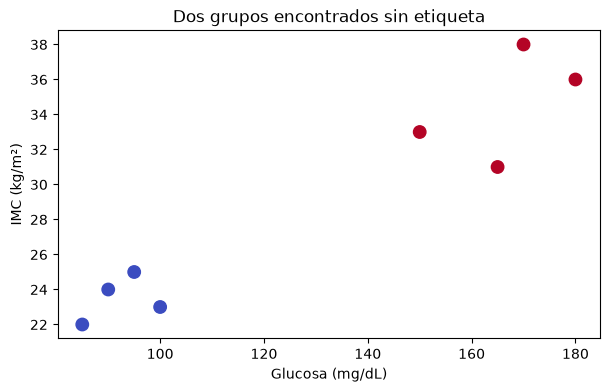

In [5]:
plt.scatter(juguete["glucosa"], juguete["imc"], c=juguete["grupo"], cmap="coolwarm", s=80)
plt.xlabel("Glucosa (mg/dL)"); plt.ylabel("IMC (kg/m²)"); plt.title("Dos grupos encontrados sin etiqueta")
plt.show()

Nadie le dijo quién es diabético. El algoritmo encontró dos grupos porque los datos **sí** tienen dos nubes. Con datos reales las nubes casi nunca están tan separadas; ese es el reto de hoy.

## Bloque 2 · Los datos reales: PIMA


### El dataset
| Campo | Valor |
|---|---|
| Nombre | Pima Indians Diabetes Database |
| Origen | National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK), publicado en el repositorio UCI y Kaggle |
| Población | 768 mujeres de 21 años o más, de herencia pima (Arizona, EE. UU.) |
| Licencia | Uso abierto para investigación y docencia (CC0 en Kaggle) |
| Por qué | Es la base tabular real que muchos equipos usan para R07, y la usamos en la semana 9 |

Es el **mismo** archivo de la semana 9. Lo descargamos de nuevo en una carpeta propia para esta semana.

In [6]:
DATOS = Path("datos_s10")
DATOS.mkdir(exist_ok=True)
URL_PIMA = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

if not (DATOS / "pima.csv").exists():
    pd.read_csv(URL_PIMA, header=None).to_csv(DATOS / "pima.csv", header=False, index=False)
print("Listo:", (DATOS / "pima.csv").resolve())

Listo: D:\cursos 2026-1\salud digital\2026-2\c10\datos_s10\pima.csv


In [7]:
COLUMNAS = ["embarazos", "glucosa", "presion", "pliegue", "insulina",
            "imc", "pedigri", "edad", "diabetes"]
pima = pd.read_csv(DATOS / "pima.csv", header=None, names=COLUMNAS)
pima.head()

,embarazos,glucosa,presion,pliegue,insulina,imc,pedigri,edad,diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Un problema conocido: los ceros
Una glucosa de 0 mg/dL o una presión de 0 mmHg son **imposibles** en una persona viva. En este dataset el 0 significa *no medido*. Contemos cuántos hay.

In [8]:
(pima == 0).sum()

embarazos    111
glucosa        5
presion       35
pliegue      227
insulina     374
imc           11
pedigri        0
edad           0
diabetes     500
dtype: int64

### Cómo leerlo y qué decidimos
- `embarazos = 0` y `diabetes = 0` son valores **reales**: no se tocan.
- `glucosa`, `presion` e `imc` en 0 son pocos: los marcamos como faltantes y quitamos esas filas.
- `insulina` (374 ceros, casi la mitad) y `pliegue` (227) tienen demasiados faltantes: **no** las usamos para agrupar. Imputar la mitad de una variable inventaría la estructura que queremos descubrir.

In [9]:
for col in ["glucosa", "presion", "imc"]:
    pima.loc[pima[col] == 0, col] = np.nan
pima = pima.dropna(subset=["glucosa", "presion", "imc"]).reset_index(drop=True)
verificar("quedan 724 pacientes", len(pima) == 724, f"({len(pima)})")

[OK   ] quedan 724 pacientes (724)


True

### Separar la etiqueta
Esta es la decisión más importante del día: la columna `diabetes` **no participa** en el agrupamiento. La guardamos aparte y solo la miraremos al final, para preguntarnos si los grupos tienen sentido clínico (lo que se llama *validación externa*).

In [10]:
VARIABLES = ["glucosa", "imc", "edad", "presion", "embarazos", "pedigri"]
X = pima[VARIABLES]
y = pima["diabetes"]          # guardada, no se usa para agrupar
X.describe().round(2)

,glucosa,imc,edad,presion,embarazos,pedigri
count,724.00,724.00,724.00,724.00,724.00,724.00
mean,121.88,32.47,33.35,72.40,3.87,0.47
std,30.75,6.89,11.77,12.38,3.36,0.33
min,44.00,18.20,21.00,24.00,0.00,0.08
25%,99.75,27.50,24.00,64.00,1.00,0.24
50%,117.00,32.40,29.00,72.00,3.00,0.38
75%,142.00,36.60,41.00,80.00,6.00,0.63
max,199.00,67.10,81.00,122.00,17.00,2.42


## Bloque 3 · Escalar: el paso que más se olvida


### Por qué importa
K-means agrupa por **distancia**. La distancia euclidiana suma diferencias al cuadrado, y no sabe que la glucosa va de 44 a 199 mientras el pedigrí va de 0.08 a 2.42.

Tres pacientes inventadas:
- **A**: glucosa 100, pedigrí 0.2
- **B**: glucosa 112, pedigrí 0.2 (12 mg/dL más: diferencia clínicamente pequeña)
- **C**: glucosa 100, pedigrí 1.2 (carga familiar enorme: unas tres desviaciones estándar)

**Pregunta para pensar:** ¿cuál se parece más a A, B o C?

In [11]:
tres = pd.DataFrame({"glucosa": [100, 112, 100], "pedigri": [0.2, 0.2, 1.2]}, index=["A", "B", "C"])

def distancia(t, a, b):
    return float(np.sqrt(((t.loc[a] - t.loc[b]) ** 2).sum()))

print("Sin escalar   A-B:", round(distancia(tres, "A", "B"), 2), "  A-C:", round(distancia(tres, "A", "C"), 2))

Sin escalar   A-B: 12.0   A-C: 1.0


Sin escalar, C parece **mucho** más cercana a A: la diferencia de pedigrí (1.0) es "pequeña" en números absolutos. Ahora dividimos cada variable por su desviación estándar en PIMA.

In [12]:
tres_esc = tres / X[["glucosa", "pedigri"]].std()
print("Escalado      A-B:", round(distancia(tres_esc, "A", "B"), 2), "  A-C:", round(distancia(tres_esc, "A", "C"), 2))

Escalado      A-B: 0.39   A-C: 3.01


Se invirtió: escalado, B es la más parecida a A. **Sin escalar, los grupos los decide la variable con números más grandes**, no la clínica.

### `StandardScaler`
Transforma cada variable a media 0 y desviación 1 (puntaje *z*): $z = \frac{x - \mu}{\sigma}$.

In [13]:
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler()
Z = escalador.fit_transform(X)
pd.DataFrame(Z, columns=VARIABLES).describe().loc[["mean", "std"]].round(2)

,glucosa,imc,edad,presion,embarazos,pedigri
mean,-0.0,-0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


In [14]:
verificar("todas las medias quedaron en 0", np.allclose(Z.mean(axis=0), 0))

[OK   ] todas las medias quedaron en 0 


True

## Bloque 4 · K-means, paso a paso


### El algoritmo
1. Elegir `k` centros iniciales (centroides).
2. **Asignar** cada paciente al centroide más cercano.
3. **Actualizar** cada centroide al promedio de sus pacientes.
4. Repetir 2 y 3 hasta que nada cambie.

Lo que minimiza es la **inercia**: la suma de las distancias al cuadrado de cada paciente a su centroide. Menor inercia = grupos más compactos.

Hagamos una vuelta **a mano** con el ejemplo de juguete, para ver que no hay magia. Empezamos con dos centroides elegidos al azar: los pacientes 0 y 1.

In [15]:
puntos = juguete[["glucosa", "imc"]].to_numpy(dtype=float)
centroides = puntos[[0, 1]].copy()
centroides

array([[85., 22.],
       [90., 24.]])

**Paso 2 · Asignar.** Distancia de cada paciente a cada centroide; cada uno se va con el más cercano.

In [16]:
dist = np.linalg.norm(puntos[:, None, :] - centroides[None, :, :], axis=2)
asignacion = dist.argmin(axis=1)
asignacion

array([0, 1, 1, 1, 1, 1, 1, 1])

**Paso 3 · Actualizar.** Cada centroide pasa al promedio de sus pacientes.

In [17]:
centroides = np.array([puntos[asignacion == j].mean(axis=0) for j in range(2)])
centroides.round(1)

array([[ 85. ,  22. ],
       [135.7,  30. ]])

Ejecuta las **dos celdas anteriores otra vez** (asignar y actualizar). En la segunda vuelta los pacientes 1, 2 y 3 se pasan al primer grupo; en la tercera, la asignación ya no cambia: el algoritmo terminó.

### Ahora con PIMA y scikit-learn
Usamos `k = 3` de manera **provisional**; en el Bloque 5 justificaremos ese número.
- `n_init=10`: corre 10 veces con distintos centroides iniciales y se queda con la de menor inercia.
- `random_state`: hace el resultado reproducible.

In [18]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=SEMILLA)
pima["cluster"] = km3.fit_predict(Z)
pima["cluster"].value_counts().sort_index()

cluster
0    323
1    222
2    179
Name: count, dtype: int64

### Los centroides, en unidades clínicas
`km3.cluster_centers_` está en puntajes *z*, que nadie en una clínica entiende. `inverse_transform` los devuelve a mg/dL, kg/m², años...

In [19]:
centros = pd.DataFrame(escalador.inverse_transform(km3.cluster_centers_), columns=VARIABLES)
centros.round(1)

,glucosa,imc,edad,presion,embarazos,pedigri
0,105.4,29.1,26.2,64.8,2.3,0.4
1,133.7,32.6,46.9,77.4,7.7,0.5
2,137.1,38.3,29.6,79.9,2.0,0.6


### ¿Por qué `n_init`? La semilla importa
Con una sola inicialización, distintas semillas pueden terminar en soluciones distintas (mínimos locales).

In [20]:
for semilla in range(5):
    inercia = KMeans(n_clusters=3, n_init=1, random_state=semilla).fit(Z).inertia_
    print(f"semilla {semilla}: inercia {inercia:.1f}")

semilla 0: inercia 2872.2
semilla 1: inercia 2877.4
semilla 2: inercia 2872.2
semilla 3: inercia 2877.8
semilla 4: inercia 2872.3


Las inercias no son todas iguales: algunas semillas caen en una solución peor. `n_init=10` reduce ese riesgo. En un microservicio, además, fijamos la semilla para que el mismo paciente quede siempre en el mismo grupo.

## Bloque 5 · ¿Cuántos grupos? (lo que R07 pide justificar)


### Tres criterios
| Criterio | Qué mide | Se busca |
|---|---|---|
| **Codo** (inercia) | Compacidad. Siempre baja al subir `k` | El punto donde deja de bajar mucho |
| **Silueta** | Para cada paciente: $s = \frac{b - a}{\max(a, b)}$, con $a$ = distancia media a su grupo y $b$ = a el grupo vecino. Va de −1 a 1 | El máximo. Mayor de 0.5 = estructura clara; alrededor de 0.2 = grupos que se tocan |
| **Davies-Bouldin** | Cuánto se parecen los grupos entre sí | El mínimo |

Calculamos los tres para `k` de 2 a 8.

In [21]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

filas = []
for k in range(2, 9):
    modelo_k = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
    etiquetas = modelo_k.labels_
    filas.append({"k": k, "inercia": round(modelo_k.inertia_),
                  "silueta": round(silhouette_score(Z, etiquetas), 3),
                  "davies_bouldin": round(davies_bouldin_score(Z, etiquetas), 2)})
criterios = pd.DataFrame(filas).set_index("k")
criterios

,inercia,silueta,davies_bouldin
k,,,
2,3352,0.237,1.72
3,2872,0.210,1.70
4,2600,0.189,1.59
5,2412,0.181,1.69
6,2257,0.179,1.60
7,2133,0.160,1.61
8,2010,0.155,1.57


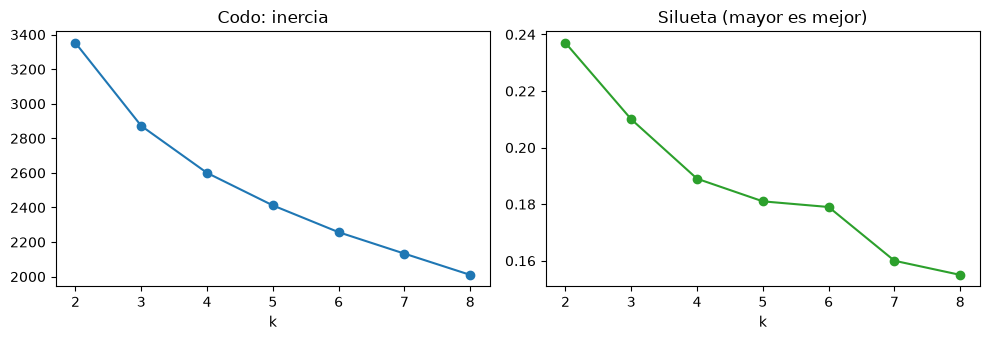

In [22]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
criterios["inercia"].plot(ax=ejes[0], marker="o", title="Codo: inercia")
criterios["silueta"].plot(ax=ejes[1], marker="o", color="tab:green", title="Silueta (mayor es mejor)")
for eje in ejes:
    eje.set_xlabel("k")
plt.tight_layout(); plt.show()

### Cómo leerlo (y lo que escribirías en `DATASETS.md`)
- La **silueta es baja para todos los `k`** (alrededor de 0.2). Es honesto decirlo: en PIMA los pacientes forman un continuo, no islas separadas. Esto es lo normal en datos clínicos.
- La silueta máxima está en `k = 2`, pero esa partición solo separa "jóvenes con glucosa normal" de "todo lo demás", que no ayuda a decidir nada.
- El codo se dobla entre 3 y 4, y `k = 3` tiene casi la misma silueta que `k = 2`.
- En el Bloque 7 veremos que con `k = 3` aparecen tres perfiles **clínicamente distintos**.

**Conclusión:** elegimos `k = 3` por el codo, una silueta cercana al máximo y la interpretación clínica. Las métricas **orientan**; la decisión final es clínica y debe quedar escrita.

### ¿Hay pacientes mal ubicados?
La silueta individual negativa indica pacientes más cerca de otro grupo que del suyo.

In [23]:
from sklearn.metrics import silhouette_samples

pima["silueta"] = silhouette_samples(Z, pima["cluster"])
pima.groupby("cluster")["silueta"].agg(["mean", lambda s: (s < 0).sum()]).set_axis(
    ["silueta_media", "pacientes_con_silueta_negativa"], axis=1).round(3)

,silueta_media,pacientes_con_silueta_negativa
cluster,,
0,0.308,0
1,0.167,21
2,0.089,49


## Bloque 6 · Ver los grupos: reducción de dimensión


### PCA
Tenemos 6 variables; una pantalla tiene 2 ejes. El **Análisis de Componentes Principales** busca las direcciones en que los pacientes más varían y proyecta sobre ellas. La primera componente (PC1) recoge la mayor variación posible; la segunda (PC2), la mayor que queda, perpendicular a la primera.

In [24]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEMILLA)
P = pca.fit_transform(Z)
print("Varianza explicada:", pca.explained_variance_ratio_.round(3),
      "| total:", round(pca.explained_variance_ratio_.sum(), 3))

Varianza explicada: [0.327 0.214] | total: 0.541


Con dos componentes vemos un poco más del 50 % de la variación: el dibujo es **útil pero incompleto**. Grupos que se ven montados en 2D pueden estar separados en las otras dimensiones.

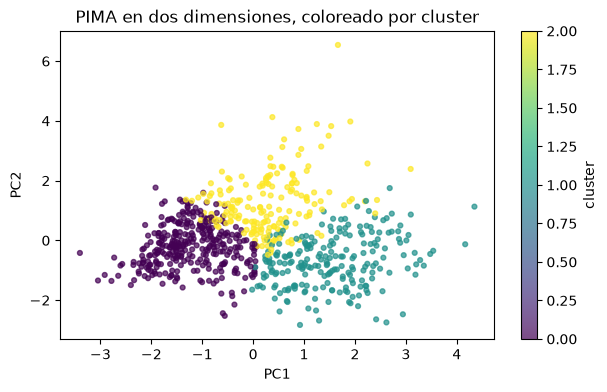

In [25]:
plt.scatter(P[:, 0], P[:, 1], c=pima["cluster"], cmap="viridis", s=12, alpha=0.7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PIMA en dos dimensiones, coloreado por cluster")
plt.colorbar(label="cluster"); plt.show()

### ¿Qué significa cada eje?
Las **cargas** dicen cuánto aporta cada variable a cada componente.

In [26]:
pd.DataFrame(pca.components_.T, index=VARIABLES, columns=["PC1", "PC2"]).round(2)

,PC1,PC2
glucosa,0.40,0.30
imc,0.27,0.60
edad,0.55,-0.33
presion,0.47,0.14
embarazos,0.48,-0.43
pedigri,0.10,0.48


**Cómo leerlo:** en PC1 todas las cargas son positivas, sobre todo edad, embarazos, presión y glucosa: es un eje de "carga metabólica que crece con la edad". En PC2 pesan IMC y antecedente familiar en un sentido, y embarazos y edad en el contrario: un eje de "obesidad y carga familiar en mujeres jóvenes con pocos embarazos". Ya se adivinan los grupos del Bloque 7.

### t-SNE 
t-SNE conserva **vecindarios**, no distancias. Sirve para dibujar; **nunca** se agrupa sobre su resultado, y las distancias entre nubes en un t-SNE no significan nada. UMAP es una alternativa más rápida con el mismo cuidado.

el t-SNE es un algoritmo de reducción de dimensionalidad no lineal que se utiliza principalmente para la visualización de datos de alta dimensión en un espacio de menor dimensión (generalmente 2D o 3D).  A diferencia de PCA, que es un método lineal, t-SNE se enfoca en preservar las relaciones locales entre los puntos de datos, lo que significa que intenta mantener los puntos similares cerca unos de otros en el espacio reducido.

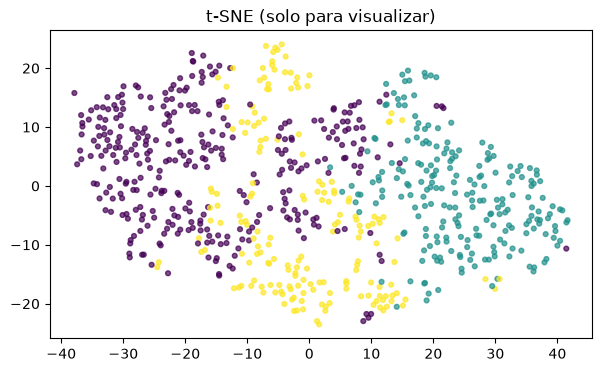

In [27]:
from sklearn.manifold import TSNE

T = TSNE(n_components=2, perplexity=30, random_state=SEMILLA).fit_transform(Z)
plt.scatter(T[:, 0], T[:, 1], c=pima["cluster"], cmap="viridis", s=12, alpha=0.7)
plt.title("t-SNE (solo para visualizar)"); plt.show()

## Bloque 7 · Interpretar los grupos clínicamente


### El perfil de cada grupo
Promedio de cada variable por grupo y, al lado, el promedio de toda la cohorte.

In [28]:
perfil = pima.groupby("cluster")[VARIABLES].mean()
perfil.loc["cohorte"] = pima[VARIABLES].mean()
perfil.assign(n=pima["cluster"].value_counts()).round(1)

,glucosa,imc,edad,presion,embarazos,pedigri,n
cluster,,,,,,,
0,105.4,29.1,26.2,64.8,2.3,0.4,323.0
1,133.7,32.6,46.9,77.4,7.7,0.5,222.0
2,137.1,38.3,29.6,79.9,2.0,0.6,179.0
cohorte,121.9,32.5,33.4,72.4,3.9,0.5,NaN


Más fácil de leer en puntajes *z* del centroide: cuántas desviaciones estándar está cada grupo por encima (+) o por debajo (−) del promedio.

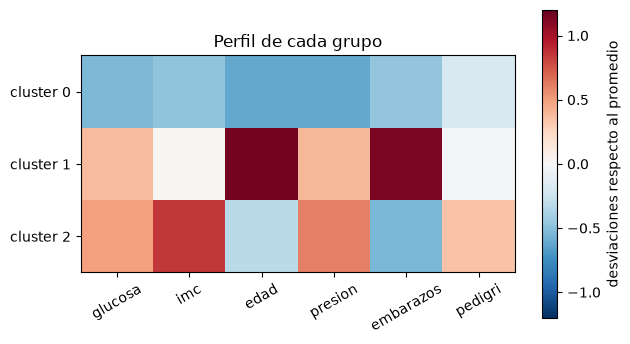

In [29]:
perfil_z = (pima.groupby("cluster")[VARIABLES].mean() - X.mean()) / X.std()
plt.imshow(perfil_z, cmap="RdBu_r", vmin=-1.2, vmax=1.2)
plt.xticks(range(len(VARIABLES)), VARIABLES, rotation=30); plt.yticks(range(3), [f"cluster {c}" for c in perfil_z.index])
plt.colorbar(label="desviaciones respecto al promedio"); plt.title("Perfil de cada grupo"); plt.show()

### Ahora sí: la etiqueta
Solo ahora miramos `diabetes`. Si los grupos tienen sentido clínico, la proporción de diabetes debería ser distinta entre ellos, **aunque el algoritmo nunca la vio**.

In [30]:
pd.crosstab(pima["cluster"], y, normalize="index").round(2).rename(columns={0: "sin_diabetes", 1: "con_diabetes"})

diabetes,sin_diabetes,con_diabetes
cluster,,
0,0.86,0.14
1,0.46,0.54
2,0.53,0.47


### La zona de confusión (lo que R07 pide explícitamente)
¿En qué grupo se equivoca **el modelo supervisado de la semana 9**? Entrenamos la misma regresión logística con validación cruzada (cada paciente se predice con un modelo que no la vio) y medimos el error por grupo.

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

prob = cross_val_predict(LogisticRegression(max_iter=1000), Z, y, cv=5, method="predict_proba")[:, 1]
pima["error_modelo"] = (prob >= 0.5).astype(int) != y
print("Error global del modelo supervisado:", round(pima["error_modelo"].mean(), 3))

Error global del modelo supervisado: 0.228


In [32]:
zona = pima.groupby("cluster").agg(n=("diabetes", "size"), tasa_diabetes=("diabetes", "mean"),
                                   tasa_error=("error_modelo", "mean")).round(3)
zona["zona_confusion"] = zona["tasa_error"] > pima["error_modelo"].mean()
zona

,n,tasa_diabetes,tasa_error,zona_confusion
cluster,,,,
0,323,0.139,0.142,False
1,222,0.541,0.315,True
2,179,0.469,0.274,True


### Cómo leerlo
- Un grupo con **poca diabetes y poco error**: el modelo acierta casi siempre (casi todas son sanas).
- Los grupos con diabetes **cercana al 50 %** son donde el modelo más se equivoca: ahí sanas y diabéticas se parecen en las variables que medimos. Esa es la **zona de confusión**.

Los números de cluster (0, 1, 2) dependen de la inicialización y pueden cambiar con otra versión de scikit-learn. Por eso los nombramos **por su perfil**, con código, y no a mano.

In [33]:
c_bajo = zona["tasa_diabetes"].idxmin()                              # menor diabetes
c_mayor = perfil_z["edad"].drop(c_bajo).idxmax()                     # el de mayor edad entre los otros
c_joven_obeso = ({0, 1, 2} - {c_bajo, c_mayor}).pop()

NOMBRES = {
    c_bajo: "Jóvenes normoglucémicas: bajo riesgo",
    c_mayor: "Mayores multíparas con glucosa elevada: zona de confusión",
    c_joven_obeso: "Jóvenes con obesidad, hipertensión y glucosa alta: zona de confusión",
}
zona.assign(nombre=pd.Series(NOMBRES))

,n,tasa_diabetes,tasa_error,zona_confusion,nombre
cluster,,,,,
0,323,0.139,0.142,False,Jóvenes normoglucémicas: bajo riesgo
1,222,0.541,0.315,True,Mayores multíparas con glucosa elevada: zona d...
2,179,0.469,0.274,True,"Jóvenes con obesidad, hipertensión y glucosa a..."


### Del grupo a la decisión
| Grupo | Decisión clínica que apoya | Decisión administrativa que apoya |
|---|---|---|
| Bajo riesgo | Tamizaje rutinario según guía | No priorizar en programas de seguimiento |
| Mayores multíparas | **No** confiar solo en el modelo: pedir prueba confirmatoria (HbA1c o curva de tolerancia) | Agendar control con laboratorio |
| Jóvenes con obesidad | Intervención en estilo de vida y control de presión; confirmar glucosa | Inscribir en programa de riesgo cardiometabólico |

Esto es lo que el requisito R07 llama "interpretar los grupos en términos de la problemática". Va en `docs/DATASETS.md` y se defiende en la sustentación.

In [34]:
verificar("al menos un grupo marcado como zona de confusión", zona["zona_confusion"].any())

[OK   ] al menos un grupo marcado como zona de confusión 


np.True_

## Bloque 8 · Otros algoritmos de agrupación


K-means supone grupos redondos y de tamaño parecido, y obliga a cada paciente a pertenecer a **un** grupo. Tres alternativas con supuestos distintos.

### 8.1 · Agrupación jerárquica
Empieza con cada paciente como su propio grupo y **une** los dos más parecidos, una y otra vez, hasta tener uno solo. El resultado es un árbol (**dendrograma**); cortarlo a una altura da `k` grupos. Con el método de **Ward**, en cada paso se une el par que menos aumenta la varianza interna.

un dendrograma es un modelo jerárquico que representa la relación entre los datos y los clusters formados.  Se construye a partir de las distancias entre los puntos de datos y permite visualizar cómo se agrupan los datos en diferentes niveles de similitud. se puede leer de abajo hacia arriba, y cada bifurcación representa un punto en el que se unen dos clusters.

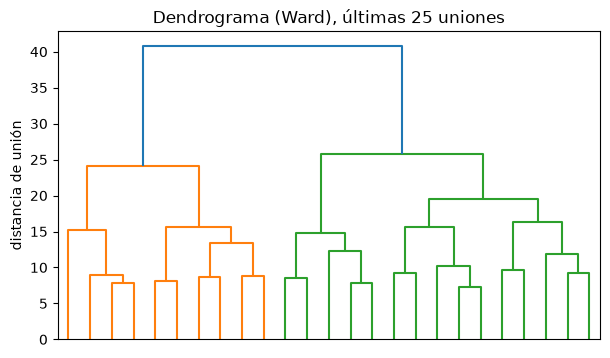

In [35]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

arbol = linkage(Z, method="ward")
dendrogram(arbol, truncate_mode="lastp", p=25, no_labels=True)
plt.title("Dendrograma (Ward), últimas 25 uniones"); plt.ylabel("distancia de unión"); plt.show()

**Cómo leerlo:** los saltos verticales largos indican que se unieron grupos muy distintos. Cortar justo debajo de un salto grande es una forma de elegir `k`. Cortamos en 3 y comparamos con K-means.

In [36]:
pima["jerarquico"] = fcluster(arbol, t=3, criterion="maxclust")
pd.crosstab(pima["cluster"], pima["jerarquico"], rownames=["kmeans"], colnames=["jerárquico"])

jerárquico,1,2,3
kmeans,,,
0,299,10,14
1,10,23,189
2,97,38,44


El **índice de Rand ajustado (ARI)** mide el acuerdo entre dos particiones sin importar cómo se numeran los grupos: 1 = idénticas, 0 = acuerdo por azar.

In [37]:
from sklearn.metrics import adjusted_rand_score

print("ARI K-means vs jerárquico:", round(adjusted_rand_score(pima["cluster"], pima["jerarquico"]), 2))

ARI K-means vs jerárquico: 0.45


Un acuerdo moderado. Cuando dos métodos con supuestos distintos coinciden **solo en parte**, los grupos no son islas: hay pacientes en la frontera. Esto confirma lo que dijo la silueta.

### 8.2 · Mezcla de gaussianas (GMM): pertenencia suave
GMM supone que cada grupo es una campana (gaussiana) con su propia forma y orientación. En vez de decir "pertenece al grupo 1", dice "**70 %** grupo 1, **28 %** grupo 2". Clínicamente es más honesto: hay pacientes que están entre dos perfiles.

Lo iniciamos en los centroides de K-means para que la numeración coincida.

In [38]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, means_init=km3.cluster_centers_, random_state=SEMILLA).fit(Z)
probs = gmm.predict_proba(Z)
pd.DataFrame(probs[:5], columns=["p_0", "p_1", "p_2"]).round(3)

,p_0,p_1,p_2
0,0.000,1.000,0.000
1,0.352,0.212,0.436
2,0.000,0.969,0.031
3,0.997,0.002,0.002
4,0.000,0.000,1.000


Definimos la **zona gris**: pacientes cuya probabilidad máxima es menor a 0.6. No pertenecen claramente a ningún grupo.

In [39]:
pima["zona_gris"] = probs.max(axis=1) < 0.6
print("Pacientes en zona gris:", pima["zona_gris"].sum(), f"({pima['zona_gris'].mean():.0%})")
pd.crosstab(pima["zona_gris"], y, normalize="index").round(2)

Pacientes en zona gris: 56 (8%)


diabetes,0,1
zona_gris,,
False,0.66,0.34
True,0.59,0.41


**Pregunta para pensar:** ¿qué harías con un paciente en zona gris en un sistema de apoyo a la decisión? (Pista: el microservicio de la Parte C lo marcará con una bandera.)

GMM también trae su criterio para elegir `k`: el **BIC**, que premia el ajuste y castiga la complejidad. Menor es mejor.

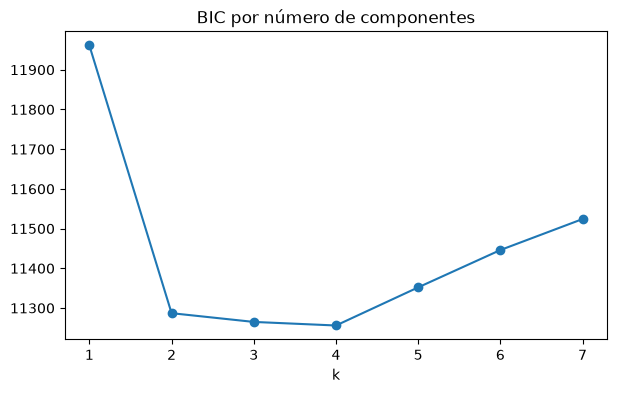

In [40]:
bic = {k: GaussianMixture(n_components=k, n_init=3, random_state=SEMILLA).fit(Z).bic(Z) for k in range(1, 8)}
pd.Series(bic).round(0).plot(marker="o", title="BIC por número de componentes"); plt.xlabel("k"); plt.show()

El BIC baja mucho de 1 a 2 y luego queda casi plano entre 2 y 4. Otra vez: no hay un `k` "verdadero"; hay un rango razonable, y dentro de él decide la interpretación clínica.

### 8.3 · DBSCAN: grupos por densidad y ruido
DBSCAN no pide `k`. Un grupo es una región **densa**: un punto con al menos `min_samples` vecinos a distancia `eps`. Lo que no cae en ninguna región densa es **ruido** (`-1`). Encuentra grupos de cualquier forma.

Para elegir `eps` se usa la gráfica de **distancia al k-ésimo vecino**: se busca el codo.

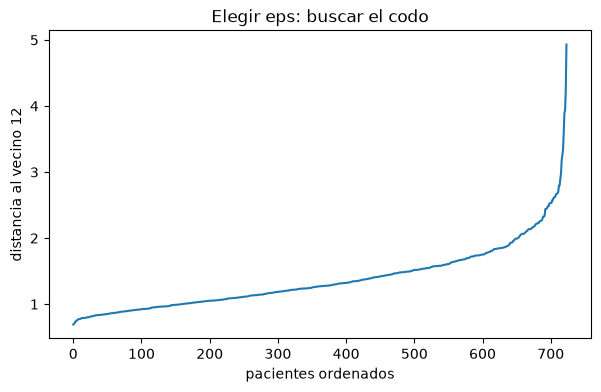

In [41]:
from sklearn.neighbors import NearestNeighbors

MIN_MUESTRAS = 12                      # regla práctica: 2 x número de variables
distancias, _ = NearestNeighbors(n_neighbors=MIN_MUESTRAS).fit(Z).kneighbors(Z)
plt.plot(np.sort(distancias[:, -1])); plt.ylabel(f"distancia al vecino {MIN_MUESTRAS}")
plt.xlabel("pacientes ordenados"); plt.title("Elegir eps: buscar el codo"); plt.show()

In [42]:
from sklearn.cluster import DBSCAN

for eps in [1.2, 1.6, 2.0]:
    etiquetas = DBSCAN(eps=eps, min_samples=MIN_MUESTRAS).fit_predict(Z)
    print(f"eps={eps}:", pd.Series(etiquetas).value_counts().sort_index().to_dict())

eps=1.2: {-1: 264, 0: 460}
eps=1.6: {-1: 62, 0: 662}
eps=2.0: {-1: 17, 0: 707}


### Cómo leerlo
DBSCAN encuentra **un solo grupo denso** y un número de pacientes "ruido" que depende de `eps`. Es la confirmación final: en PIMA no hay islas separadas por zonas vacías. Aun así DBSCAN sirve para otra cosa: su ruido son **pacientes atípicos** que vale la pena revisar (¿error de digitación?, ¿caso raro?).

In [43]:
ruido = DBSCAN(eps=2.0, min_samples=MIN_MUESTRAS).fit_predict(Z) == -1
pima.loc[ruido, VARIABLES + ["diabetes"]].head(8)

,glucosa,imc,edad,presion,embarazos,pedigri,diabetes
4,137.0,43.1,33,40.0,0,2.288,1
40,171.0,45.4,54,110.0,9,0.721,1
42,180.0,42.0,25,66.0,0,1.893,1
54,146.0,40.5,44,82.0,0,1.781,0
98,96.0,22.4,27,122.0,1,0.207,0
117,88.0,55.0,26,30.0,1,0.496,1
167,129.0,67.1,26,110.0,0,0.319,1
215,197.0,36.7,31,70.0,4,2.329,0


### 8.4 · Resumen: cuál usar
| Algoritmo | Necesita `k` | Forma de los grupos | Pertenencia | Atípicos | Úsalo cuando |
|---|---|---|---|---|---|
| K-means | Sí | Redondos, tamaños parecidos | Dura | No | Quieres perfiles simples y un servicio rápido |
| Jerárquico | No (se corta el árbol) | Según el enlace | Dura | No | Pocos pacientes y quieres ver la estructura completa |
| GMM | Sí (BIC ayuda) | Elípticos, distinto tamaño | **Suave** | Indirecto | Importa saber quién está entre dos perfiles |
| DBSCAN | No (pide `eps`) | Cualquiera | Dura | **Sí** | Grupos de forma rara o buscar casos atípicos |

## Bloque 9 · Aumento de datos por clusters (R07)


### Por qué dentro de cada grupo
La semana pasada generamos sintéticos interpolando vecinos. R07 pide algo más preciso: **generar dentro de cada grupo**. Si generamos con la media y la covarianza de **toda** la cohorte, mezclamos fenotipos: puede salir una "paciente de 22 años con 12 embarazos", porque en la cohorte completa edad y embarazos se combinan de cualquier manera. Dentro de un grupo, las relaciones entre variables son las de ese perfil.

### El método
Para cada grupo: calcular su media y su matriz de covarianza, muestrear de una **normal multivariada** y **recortar** a rangos clínicamente plausibles (el curso penaliza valores imposibles).

In [44]:
RANGOS = {
    "glucosa": (44, 199), "imc": (18.2, 67.1), "edad": (21, 81),
    "presion": (24, 122), "embarazos": (0, 17), "pedigri": (0.078, 2.42),
}

In [45]:
def generar_en_cluster(grupo, n, rng):
    nuevos = pd.DataFrame(rng.multivariate_normal(grupo[VARIABLES].mean(), grupo[VARIABLES].cov(), size=n),
                          columns=VARIABLES)
    for v, (lo, hi) in RANGOS.items():
        nuevos[v] = nuevos[v].clip(lo, hi)
    enteras = ["glucosa", "presion", "edad", "embarazos"]
    nuevos[enteras] = nuevos[enteras].round().astype(int)
    return nuevos.round({"imc": 1, "pedigri": 3})

Generamos **200** sintéticos, repartidos en proporción al tamaño de cada grupo, y marcamos su origen y su grupo, como exige R07.

In [46]:
rng = np.random.default_rng(SEMILLA)
partes = []
for c, grupo in pima.groupby("cluster"):
    n = round(200 * len(grupo) / len(pima))
    partes.append(generar_en_cluster(grupo, n, rng).assign(cluster=c))
sinteticos = pd.concat(partes, ignore_index=True).assign(origen="sintetico")
sinteticos["cluster"].value_counts().sort_index()

cluster
0    89
1    61
2    49
Name: count, dtype: int64

In [47]:
fuera = sum(((sinteticos[v] < lo) | (sinteticos[v] > hi)).sum() for v, (lo, hi) in RANGOS.items())
verificar("ningún sintético fuera de rango clínico", fuera == 0)
verificar("cerca de 200 sintéticos", abs(len(sinteticos) - 200) <= 2, f"({len(sinteticos)})")

[OK   ] ningún sintético fuera de rango clínico 
[OK   ] cerca de 200 sintéticos (199)


True

Si el redondeo dio 199 o 201, no es un error: es el reparto proporcional. El microservicio corregirá eso haciendo que el último grupo complete el total.

### ¿Se reconocen en su grupo?
Una prueba de calidad: pasamos los sintéticos por el **mismo** K-means. Si nacieron en el grupo 1, el modelo debería asignarlos al grupo 1.

In [48]:
reasignado = km3.predict(escalador.transform(sinteticos[VARIABLES]))
consistencia = (reasignado == sinteticos["cluster"]).mean()
verificar("más del 85 % se reconoce en su grupo", consistencia > 0.85, f"({consistencia:.1%})")

[OK   ] más del 85 % se reconoce en su grupo (94.0%)


np.True_

No es 100 %: algunos sintéticos nacen en la frontera, igual que algunos pacientes reales (recuerda la silueta negativa). Comparemos medias reales y sintéticas por grupo.

In [49]:
comparacion = pd.concat({"real": pima.groupby("cluster")[VARIABLES].mean(),
                         "sintetico": sinteticos.groupby("cluster")[VARIABLES].mean()}, axis=1)
comparacion.round(1)

real                                       sintetico                                      
        glucosa   imc  edad presion embarazos pedigri   glucosa   imc  edad presion embarazos pedigri
cluster                                                                                              
0         105.4  29.1  26.2    64.8       2.3     0.4     105.6  29.2  26.2    63.8       2.3     0.4
1         133.7  32.6  46.9    77.4       7.7     0.5     138.2  32.4  48.1    76.8       7.5     0.4
2         137.1  38.3  29.6    79.9       2.0     0.6     138.6  40.2  30.7    80.7       2.0     0.7

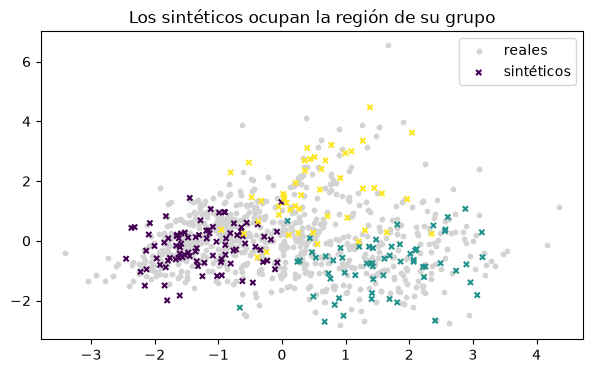

In [50]:
Ps = pca.transform(escalador.transform(sinteticos[VARIABLES]))
plt.scatter(P[:, 0], P[:, 1], c="lightgray", s=10, label="reales")
plt.scatter(Ps[:, 0], Ps[:, 1], c=sinteticos["cluster"], cmap="viridis", s=14, marker="x", label="sintéticos")
plt.legend(); plt.title("Los sintéticos ocupan la región de su grupo"); plt.show()

### Tres reglas que no se negocian
1. Un sintético **no** agrega información nueva: reproduce la que ya tenían los reales de su grupo.
2. **Nunca** se evalúa un modelo con sintéticos y se presenta como validación clínica.
3. Todo sintético queda **marcado** (`origen = sintetico`) y **ligado a su cluster**, en la base de datos y en lo que se muestre.

Fin de la Parte A. Si vas con buen tiempo, este es un buen momento para un descanso de 10 minutos.

# Parte B · Un caso administrativo: segmentar la utilización hospitalaria

## Bloque 10 · Diabetes 130-US Hospitals


### La pregunta de gestión
Una IPS (o una EPS) quiere crear un **programa de gestión de casos**: un equipo de enfermería que hace seguimiento telefónico después del alta. No puede llamar a todos. ¿A qué tipo de paciente le sirve más? ¿Qué hospitalizaciones se salen del patrón y merecen auditoría?

Aquí no hay un diagnóstico que predecir: hay que **entender cómo se usan los servicios**. Es un problema no supervisado.

### El dataset
| Campo | Valor |
|---|---|
| Nombre | Diabetes 130-US Hospitals for years 1999-2008 |
| Origen | UCI Machine Learning Repository (Strack et al., 2014, *BioMed Research International*). DOI 10.24432/C5230J |
| Contenido | 101.766 hospitalizaciones reales de pacientes con diabetes en 130 hospitales de EE. UU., anonimizadas |
| Licencia | CC BY 4.0 |
| Pesa | unos 19 MB |

La descargamos de una copia pública en GitHub (el sitio de UCI entrega un `.zip`).

In [51]:
URL_HOSP = "https://raw.githubusercontent.com/IsaacZalis/Diabetes/main/data/diabetic_data.csv"

if not (DATOS / "diabetic_data.csv").exists():
    pd.read_csv(URL_HOSP, low_memory=False).to_csv(DATOS / "diabetic_data.csv", index=False)
hosp = pd.read_csv(DATOS / "diabetic_data.csv", na_values="?", low_memory=False)
print(hosp.shape)

(101766, 50)


### Si algo falla
Si la descarga no funciona, baja el `.zip` desde la página del dataset en el repositorio UCI (busca *Diabetes 130-US Hospitals*), descomprímelo y pon `diabetic_data.csv` dentro de la carpeta `datos_s10`. Vuelve a ejecutar la celda.

### La unidad de análisis
Cada fila es una **hospitalización**, no un paciente: el mismo paciente aparece varias veces. Si lo dejamos así, los pacientes que más se hospitalizan pesarían más en los grupos. Nos quedamos con **la primera hospitalización de cada paciente**.

In [52]:
print("Hospitalizaciones:", len(hosp), "| pacientes distintos:", hosp["patient_nbr"].nunique())
hosp = hosp.sort_values("encounter_id").drop_duplicates("patient_nbr")

Hospitalizaciones: 101766 | pacientes distintos: 71518


También quitamos a quienes **murieron o fueron a cuidado paliativo** al alta (códigos de egreso 11, 13, 14, 19, 20 y 21): no pueden reingresar ni entrar a un programa de seguimiento. Ojo: esta decisión cambia la población y debe quedar escrita.

In [53]:
hosp = hosp[~hosp["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]
verificar("quedan cerca de 70.000 pacientes", 65_000 < len(hosp) < 75_000, f"({len(hosp)})")

[OK   ] quedan cerca de 70.000 pacientes (69973)


True

### Las variables de utilización
| Variable | Significado |
|---|---|
| `time_in_hospital` | Días de estancia |
| `num_lab_procedures` | Pruebas de laboratorio durante la estancia |
| `num_procedures` | Procedimientos (no de laboratorio) |
| `num_medications` | Medicamentos distintos administrados |
| `number_diagnoses` | Diagnósticos registrados |
| `visitas_previas` | Consultas externas + urgencias + hospitalizaciones **del año anterior** (la creamos sumando tres columnas) |

La readmisión (`readmitted`) la dejamos aparte, igual que hicimos con `diabetes` en PIMA.

In [54]:
hosp["visitas_previas"] = hosp["number_outpatient"] + hosp["number_emergency"] + hosp["number_inpatient"]
VARS_H = ["time_in_hospital", "num_lab_procedures", "num_procedures",
          "num_medications", "number_diagnoses", "visitas_previas"]
hosp[VARS_H].describe().round(1)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,visitas_previas
count,69973.0,69973.0,69973.0,69973.0,69973.0,69973.0
mean,4.3,42.9,1.4,15.7,7.2,0.6
std,2.9,19.9,1.8,8.3,2.0,1.4
min,1.0,1.0,0.0,1.0,1.0,0.0
25%,2.0,31.0,0.0,10.0,6.0,0.0
50%,3.0,44.0,1.0,14.0,8.0,0.0
75%,6.0,57.0,2.0,20.0,9.0,1.0
max,14.0,132.0,6.0,81.0,16.0,49.0


### Datos de conteo: muy sesgados
Fíjate en `visitas_previas`: la mediana es 0 y el máximo pasa de 40. Con esa forma, unos pocos pacientes extremos arrastran los centroides. La transformación `log(1 + x)` comprime la cola sin perder el orden.

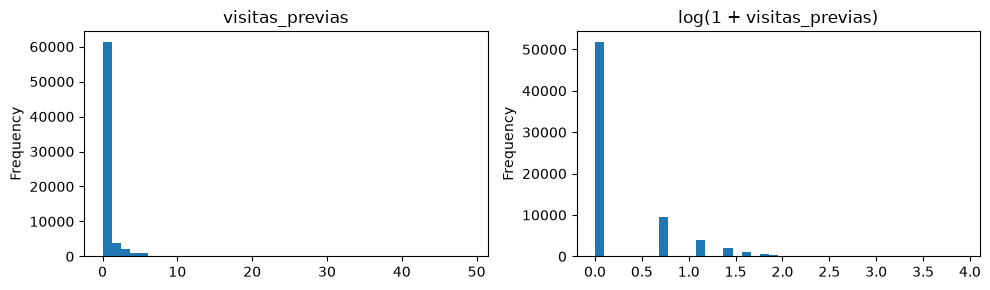

In [55]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3))
hosp["visitas_previas"].plot.hist(bins=40, ax=ejes[0], title="visitas_previas")
np.log1p(hosp["visitas_previas"]).plot.hist(bins=40, ax=ejes[1], title="log(1 + visitas_previas)")
plt.tight_layout(); plt.show()

### Muestra, transformación y escalado
Con 70.000 pacientes la silueta tarda mucho (compara cada par). Trabajamos con una **muestra aleatoria de 15.000**, suficiente para descubrir los perfiles.

In [56]:
muestra = hosp.sample(15_000, random_state=SEMILLA).copy()
escalador_h = StandardScaler()
ZH = escalador_h.fit_transform(np.log1p(muestra[VARS_H]))
ZH.shape

(15000, 6)

### ¿Cuántos segmentos?
Mismo procedimiento del Bloque 5. `sample_size` calcula la silueta sobre 5.000 pacientes para que no tarde.

In [57]:
for k in range(2, 8):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit_predict(ZH)
    print(k, round(silhouette_score(ZH, etiquetas, sample_size=5000, random_state=SEMILLA), 3))

2 0.198
3 0.204
4 0.222
5 0.204
6 0.212
7 0.196


La silueta es máxima (aunque modesta) en `k = 4`. Lo usamos y miramos los perfiles en **unidades originales** (días, pruebas, medicamentos).

In [58]:
km_h = KMeans(n_clusters=4, n_init=10, random_state=SEMILLA)
muestra["segmento"] = km_h.fit_predict(ZH)
perfil_h = muestra.groupby("segmento")[VARS_H].mean().round(1)
perfil_h.assign(n=muestra["segmento"].value_counts())

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,visitas_previas,n
segmento,,,,,,,
0,6.2,50.5,2.3,21.1,8.0,0.1,5537
1,2.8,4.7,1.3,12.2,7.1,0.4,1314
2,2.6,42.7,0.6,10.3,6.1,0.1,5451
3,4.3,47.0,1.0,16.2,8.0,2.6,2698


**Pregunta para pensar:** antes de seguir, ponle un nombre a cada segmento. ¿Cuál consume más camas? ¿Cuál tiene muchas visitas previas? ¿Hay uno con muy pocas pruebas de laboratorio? (Ese último es interesante: ¿son pacientes distintos o **hospitales que registran distinto**? Un grupo puede revelar un problema de calidad del dato, no un tipo de paciente.)

### Validación externa: la readmisión
Igual que con la diabetes en PIMA: ahora traemos el desenlace que el algoritmo no vio. Readmisión en menos de 30 días es el indicador que los pagadores vigilan.

In [59]:
muestra["readm_30"] = (muestra["readmitted"] == "<30").astype(int)
resumen_h = muestra.groupby("segmento").agg(n=("readm_30", "size"), readmision_30d=("readm_30", "mean"),
                                            dias_cama=("time_in_hospital", "sum")).round(3)
resumen_h["porcentaje_dias_cama"] = (resumen_h["dias_cama"] / resumen_h["dias_cama"].sum()).round(3)
resumen_h

,n,readmision_30d,dias_cama,porcentaje_dias_cama
segmento,,,,
0,5537,0.096,34213,0.539
1,1314,0.072,3655,0.058
2,5451,0.074,14071,0.222
3,2698,0.128,11571,0.182


### Del segmento a la decisión administrativa
Busca en tus tablas:
- El segmento con **más visitas previas** tiene la mayor readmisión: es el candidato natural al programa de gestión de casos (llamada a las 48 horas, conciliación de medicamentos, cita temprana).
- El segmento de **estancias largas y muchos medicamentos** consume la mayor parte de los días-cama: es el foco para planear camas y revisar estancias prolongadas.
- El segmento de **estancia corta y baja complejidad** es el volumen: rutas estandarizadas.

Fíjate en lo que **no** hicimos: no predijimos quién se va a readmitir (eso sería supervisado). Describimos **tipos** de uso y comprobamos que se asocian con el desenlace. Para una gerencia, a menudo eso basta para diseñar un programa.

### Detección de atípicos: Isolation Forest
Para auditoría interesa lo contrario de un grupo: lo que **no se parece a nada**. Isolation Forest construye árboles que cortan los datos al azar; un caso atípico queda aislado en pocos cortes. `contamination` es la proporción que esperamos marcar (aquí, 1 %).

ademas un isolation forest es un metodo de detección de anomalías que puede ser útil para identificar pacientes con características inusuales en el conjunto de datos hospitalarios.    A continuación, se muestra cómo aplicar Isolation Forest a los datos de hospitalización para detectar posibles outliers.

In [60]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.01, random_state=SEMILLA).fit(ZH)
muestra["atipico"] = iso.predict(ZH) == -1
muestra["puntaje_atipico"] = -iso.score_samples(ZH)        # más alto = más raro
print("Encuentros marcados:", muestra["atipico"].sum())

Encuentros marcados: 150


In [61]:
pd.concat({"atipicos": muestra.loc[muestra["atipico"], VARS_H].mean(),
           "todos": muestra[VARS_H].mean()}, axis=1).round(1)

,atipicos,todos
time_in_hospital,4.2,4.2
num_lab_procedures,18.7,43.0
num_procedures,2.3,1.4
num_medications,12.9,15.5
number_diagnoses,5.3,7.2
visitas_previas,3.5,0.6


In [62]:
muestra.sort_values("puntaje_atipico", ascending=False)[VARS_H + ["readmitted"]].head(5)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,visitas_previas,readmitted
72296,1,38,6,9,3,7,NO
7180,2,2,0,4,1,0,NO
75471,1,1,1,2,5,3,NO
34989,1,33,6,11,4,8,>30
39811,2,67,0,2,2,2,<30


### Cómo leerlo
Los atípicos tienen muchas más visitas previas y procedimientos que el promedio, pero muy **pocas** pruebas de laboratorio y diagnósticos registrados: combinaciones que casi nadie tiene. Algunos serán pacientes realmente particulares; otros, **errores o vacíos de registro**. El modelo no distingue: solo ordena la lista de revisión.

### Reflexión antes de la Parte C
- Un atípico **no es** un fraude ni un error: es un caso para que una persona revise. Usarlo para negar un servicio de forma automática sería una decisión sin sustento.
- Estos datos son de EE. UU. entre 1999 y 2008. Los perfiles de utilización de una IPS colombiana pueden ser muy distintos: el método se transfiere, los grupos no.
- Agrupar por variables que codifican raza o tipo de asegurador puede producir segmentos que **discriminan**. Por eso no las incluimos.

# Parte C · El microservicio de agrupación

## Bloque 11 · Diseño y primera etapa


### Qué vamos a construir
Un servicio nuevo, `agrupacion`, igual en espíritu al `ml` de la semana 9:

| Decisión | Por qué |
|---|---|
| **Servicio aparte** (puerto 8002) | Se puede reiniciar, versionar y escalar sin tocar la API ni el modelo supervisado. En su proyecto pueden fusionarlo con `ml` si prefieren |
| **Sin `/login` propio** | Acepta los tokens de la API porque comparten `JWT_SECRET` |
| **Se entrena al arrancar** con `pima.csv` | Mismos pasos del cuaderno; no dependemos de un archivo de modelo compilado con otra versión de scikit-learn |
| **Solo recibe variables clínicas** | Si llega un nombre o un documento, responde 422. Es la minimización de datos de R12 y de la Ley 1581/2012 |
| **Roles** | `medico`, `especialista` y `admin` consultan. Solo `admin` genera sintéticos. `paciente` y `contable`: 403 |

### Las rutas
| Método y ruta | Quién | Qué hace | Etapa |
|---|---|---|---|
| `GET /health` | Cualquiera | Estado | 1 |
| `GET /quien-soy` | Con sesión | Muestra el usuario del token | 1 |
| `GET /modelo` | Clínicos y admin | Versión, `k` y silueta | 2 |
| `GET /clusters` | Clínicos y admin | Lista de grupos: **el contrato de R07** | 2 |
| `POST /sinteticos?n=200` | Admin | Genera sintéticos por cluster | 3 |
| `GET /sinteticos` | Admin | Lista sintéticos (filtro por cluster) | 3 |
| `POST /asignar` | Médico, especialista, admin | Ubica un paciente nuevo en su grupo | 4 |

El contrato de `clusters` en el `tester.yaml` del Proyecto 2 pide: una lista de `{"cluster", "descripcion", "n_reales", "n_sinteticos"}`. Lo cumpliremos al pie de la letra.

### Cómo vamos a trabajar
1. Escribimos cada archivo con `%%writefile`. Algunos **crecen** con `%%writefile -a` (agregar al final), para que veas cómo se construyen por partes.
2. Mientras desarrollamos, el servicio corre **en tu equipo** con `uvicorn --reload` en el puerto **8102**: cada vez que una celda escribe un archivo, el servidor se recarga solo.
3. Al final (Bloque 15) lo metemos en Docker, en el puerto 8002, detrás de nginx.

### Paso 11.1 · La carpeta y los datos

In [63]:
import shutil

CARPETA = Path("agrupacion")
(CARPETA / "data").mkdir(parents=True, exist_ok=True)
shutil.copy(DATOS / "pima.csv", CARPETA / "data" / "pima.csv")
sorted(str(p) for p in CARPETA.rglob("*"))

['agrupacion\\data', 'agrupacion\\data\\pima.csv']

### Paso 11.2 · Dependencias
Versiones fijas: el contenedor de hoy y el de dentro de un mes deben instalar lo mismo.

In [64]:
%%writefile agrupacion/requirements.txt
fastapi==0.115.*
uvicorn[standard]==0.32.*
scikit-learn==1.5.*
pandas==2.2.*
numpy==2.1.*
PyJWT==2.9.*

Writing agrupacion/requirements.txt


### Paso 11.3 · Seguridad: el mismo token de la API
`usuario_actual` es idéntico al del servicio `ml` de la semana 9: lee el token, lo valida con `JWT_SECRET` y devuelve usuario y rol.

Lo nuevo es `requiere_roles`: una **fábrica de dependencias**. `requiere_roles("admin")` devuelve una función que FastAPI ejecuta antes de la ruta; si el rol no está en la lista, responde 403 y la ruta ni se ejecuta. Así cada ruta declara en una línea quién puede usarla.

In [65]:
%%writefile agrupacion/seguridad.py
"""Validación del token JWT emitido por la API (igual que el servicio ml de la semana 9).

El servicio de agrupación NO tiene /login: confía en los tokens que firma la API
porque comparte con ella el secreto JWT_SECRET.
"""
import os

import jwt
from fastapi import Depends, HTTPException
from fastapi.security import HTTPAuthorizationCredentials, HTTPBearer

JWT_SECRET = os.getenv("JWT_SECRET", "salud_digital_jwt_dev_2026")
bearer = HTTPBearer(auto_error=False)


def usuario_actual(creds: HTTPAuthorizationCredentials | None = Depends(bearer)) -> dict:
    if creds is None:
        raise HTTPException(status_code=401, detail="Falta iniciar sesión")
    try:
        datos = jwt.decode(creds.credentials, JWT_SECRET, algorithms=["HS256"])
    except jwt.ExpiredSignatureError:
        raise HTTPException(status_code=401, detail="La sesión expiró, ingresa de nuevo")
    except jwt.InvalidTokenError:
        raise HTTPException(status_code=401, detail="Sesión inválida")
    return {"id": datos.get("uid"), "username": datos["sub"], "role": datos["role"]}


def requiere_roles(*roles: str):
    """Fábrica de dependencias: deja pasar solo a los roles indicados (403 para el resto)."""
    def verificar(user: dict = Depends(usuario_actual)) -> dict:
        if user["role"] not in roles:
            raise HTTPException(status_code=403, detail=f"Rol '{user['role']}' sin permiso")
        return user
    return verificar


CLINICOS = ("medico", "especialista", "admin")

Writing agrupacion/seguridad.py


### Paso 11.4 · `main.py`, etapa 1
Solo dos rutas: `/health` (sin sesión, para saber si el servicio vive) y `/quien-soy` (para comprobar que el token se valida).

In [66]:
%%writefile agrupacion/main.py
"""Servicio de agrupación (semana 10). Crece por etapas: cada etapa agrega rutas al final."""
from fastapi import Depends, FastAPI

from seguridad import usuario_actual

app = FastAPI(title="Servicio de agrupación clínica", version="1.0")


@app.get("/health")
def health():
    return {"estado": "ok", "servicio": "agrupacion"}


@app.get("/quien-soy")
def quien_soy(user: dict = Depends(usuario_actual)):
    return user

Writing agrupacion/main.py


### Paso 11.5 · Encender el servidor en modo desarrollo
Tres funciones de apoyo:
- `encender()` lanza `uvicorn --reload` en segundo plano y guarda su salida en un archivo de registro.
- `apagar()` lo detiene (en Windows hay que cerrar también el proceso hijo que crea `--reload`).
- `esperar()` pregunta por `/health` hasta que el servidor responda.

In [73]:
import subprocess
import platform
import sys

PUERTO_DEV = 8102
REGISTRO = DATOS / "servidor_agrupacion.log"
SERVIDOR = None

def encender():
    global SERVIDOR
    extra = ({"creationflags": subprocess.CREATE_NEW_PROCESS_GROUP} if platform.system() == "Windows"
             else {"start_new_session": True})
    SERVIDOR = subprocess.Popen(
        [sys.executable, "-m", "uvicorn", "main:app", "--port", str(PUERTO_DEV), "--reload"],
        cwd=CARPETA, stdout=open(REGISTRO, "w"), stderr=subprocess.STDOUT, **extra)

In [68]:
import signal

def apagar():
    if SERVIDOR is None or SERVIDOR.poll() is not None:
        return print("No había servidor encendido.")
    if platform.system() == "Windows":
        subprocess.run(["taskkill", "/F", "/T", "/PID", str(SERVIDOR.pid)], capture_output=True)
    else:
        os.killpg(SERVIDOR.pid, signal.SIGTERM)
    SERVIDOR.wait(timeout=10)
    print("Servidor apagado.")

Para hablar con el servicio usamos la misma función `api()` de la semana 9 (con `urllib`, sin librerías extra), apuntando a otra dirección.

In [69]:
import urllib.error
import urllib.request

AG = f"http://127.0.0.1:{PUERTO_DEV}"

def api(metodo, ruta, token=None, cuerpo=None, base=AG):
    datos = json.dumps(cuerpo).encode() if cuerpo is not None else None
    peticion = urllib.request.Request(base + ruta, data=datos, method=metodo)
    if datos is not None:
        peticion.add_header("Content-Type", "application/json")
    if token:
        peticion.add_header("Authorization", "Bearer " + token)
    try:
        with urllib.request.urlopen(peticion, timeout=60) as r:
            return r.status, json.loads(r.read() or "null")
    except urllib.error.HTTPError as e:
        try:
            return e.code, json.loads(e.read())
        except Exception:
            return e.code, None

In [70]:
def esperar(segundos=25, base=AG):
    time.sleep(1.5)                                  # da tiempo a que --reload detecte el cambio
    for _ in range(segundos * 2):
        try:
            if api("GET", "/health", base=base)[0] == 200:
                return True
        except Exception:
            pass
        time.sleep(0.5)
    print("El servidor no respondió. Últimas líneas del registro:")
    print(REGISTRO.read_text(encoding="utf-8", errors="ignore")[-1500:])
    return False

Encendemos.

In [74]:
encender()
verificar("el servicio responde /health", esperar())
api("GET", "/health")

[OK   ] el servicio responde /health 


(200, {'estado': 'ok', 'servicio': 'agrupacion'})

### Paso 11.6 · Tokens para probar
En el sistema real el token sale del `/login` de la API (lo usaremos en el Bloque 15). Mientras desarrollamos, necesitamos tokens de **cinco roles**, y quizás su API todavía no tiene usuarios `especialista` o `contable`. Por eso creamos **tokens de laboratorio** firmados con el mismo secreto: es exactamente lo que hace la API al iniciar sesión.

Esto **solo** se hace en el cuaderno. El secreto nunca va en el frontend ni en el repositorio (R03).

In [75]:
import jwt

JWT_SECRET = os.getenv("JWT_SECRET", "salud_digital_jwt_dev_2026")    # el mismo de docker-compose.yml

def token_laboratorio(rol):
    datos = {"sub": f"lab_{rol}", "uid": 0, "role": rol, "exp": int(time.time()) + 3600}
    return jwt.encode(datos, JWT_SECRET, algorithm="HS256")

T = {rol: token_laboratorio(rol) for rol in ["admin", "medico", "especialista", "paciente", "contable"]}

In [76]:
estado, _ = api("GET", "/quien-soy")
verificar("sin token: 401", estado == 401)
estado, yo = api("GET", "/quien-soy", token=T["especialista"])
verificar("con token de especialista: 200", estado == 200, yo)
estado, _ = api("GET", "/quien-soy", token=T["medico"] + "x")
verificar("token alterado: 401", estado == 401)

[OK   ] sin token: 401 
[OK   ] con token de especialista: 200 {'id': 0, 'username': 'lab_especialista', 'role': 'especialista'}
[OK   ] token alterado: 401 


True

### Si algo falla
- **El servidor no responde** y el registro dice `No module named 'fastapi'` o `'uvicorn'`: el Paso 0.3 se instaló en otro Python. Revisa el Paso 0.2.
- **`[Errno 10048]` o `address already in use`**: quedó un servidor de un intento anterior. Ejecuta `apagar()`; si no basta, reinicia el *kernel* y vuelve a encender.
- **Todo da 401 con token**: el `JWT_SECRET` del cuaderno no es el mismo que lee el servicio. Los dos usan el valor por defecto si no definiste la variable.

---

## Bloque 12 · Etapa 2: el modelo y sus grupos


### Paso 12.1 · `datos.py`
La carga y limpieza del Bloque 2, ahora como módulo. Fíjate en que `VARIABLES` y `RANGOS` son **los mismos** del cuaderno: si cambian aquí y no allá, el servicio y el análisis dejan de coincidir.

In [77]:
%%writefile agrupacion/datos.py
"""El dataset REAL (PIMA) y su limpieza: la misma del cuaderno."""
from pathlib import Path

import numpy as np
import pandas as pd

RUTA = Path(__file__).parent / "data" / "pima.csv"

COLUMNAS = ["embarazos", "glucosa", "presion", "pliegue", "insulina",
            "imc", "pedigri", "edad", "diabetes"]

# Variables con las que se agrupa (sin insulina ni pliegue: demasiados faltantes)
VARIABLES = ["glucosa", "imc", "edad", "presion", "embarazos", "pedigri"]

# Rangos clínicamente plausibles: se usan para validar entradas y recortar sintéticos
RANGOS = {
    "glucosa": (44, 199), "imc": (18.2, 67.1), "edad": (21, 81),
    "presion": (24, 122), "embarazos": (0, 17), "pedigri": (0.078, 2.42),
}


def cargar_pima() -> pd.DataFrame:
    df = pd.read_csv(RUTA, header=None, names=COLUMNAS)
    for col in ["glucosa", "presion", "imc"]:
        df.loc[df[col] == 0, col] = np.nan        # 0 = no medido
    return df.dropna(subset=["glucosa", "presion", "imc"]).reset_index(drop=True)

Writing agrupacion/datos.py


### Paso 12.2 · `modelo.py`, primera parte: entrenar
Los pasos de los Bloques 3 y 4: escalar, K-means con `k = 3`, silueta. Todo queda en un diccionario `ESTADO` en memoria. `modelo()` entrena **la primera vez** que alguien lo necesita y después devuelve lo que ya está en memoria.

In [78]:
%%writefile agrupacion/modelo.py
"""Modelo de agrupación: se entrena al arrancar, con los mismos pasos del cuaderno."""
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from datos import VARIABLES, cargar_pima

K = 3            # elegido en el cuaderno (codo + silueta + interpretación clínica)
SEMILLA = 42
VERSION = "kmeans-pima-k3-v1"

ESTADO: dict = {}     # aquí queda todo lo entrenado, en memoria


def entrenar() -> dict:
    df = cargar_pima()
    escalador = StandardScaler().fit(df[VARIABLES])
    Z = escalador.transform(df[VARIABLES])
    kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(Z)
    df["cluster"] = kmeans.labels_
    ESTADO.update(df=df, escalador=escalador, kmeans=kmeans,
                  silueta=round(float(silhouette_score(Z, kmeans.labels_)), 3))
    return ESTADO


def modelo() -> dict:
    """Devuelve el modelo, entrenándolo la primera vez que alguien lo pide."""
    return ESTADO if ESTADO else entrenar()

Writing agrupacion/modelo.py


### Paso 12.3 · `modelo.py`, segunda parte: describir los grupos
El Bloque 7 convertido en función. Para cada grupo:
1. Calcula el puntaje *z* del centroide y nombra en palabras las variables que se alejan al menos 0.4 desviaciones del promedio (`RASGOS`).
2. Agrega la tasa de diabetes del grupo (validación externa).
3. Calcula dónde se equivoca la regresión logística y marca la **zona de confusión**.

La descripción se genera **desde los datos**: si alguien reentrena con otro `k`, las descripciones siguen siendo correctas. Escribir los nombres a mano en el código haría que mintieran después del primer cambio.

Esta celda **agrega** (`-a`) al final de `modelo.py`.

In [79]:
%%writefile -a agrupacion/modelo.py


# ---- Etapa 2b: describir cada grupo en lenguaje clínico ----
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

# Cómo se dice en palabras que un grupo está por encima o por debajo del promedio
RASGOS = {"glucosa": ("glucosa alta", "glucosa baja"), "imc": ("IMC alto", "IMC bajo"),
          "edad": ("mayor edad", "menor edad"), "presion": ("presión alta", "presión baja"),
          "embarazos": ("más embarazos", "menos embarazos"),
          "pedigri": ("más carga familiar", "menos carga familiar")}


def tasa_de_error_supervisado(df) -> np.ndarray:
    """Dónde se equivoca la regresión logística de la semana 9 (validación cruzada)."""
    Z = ESTADO["escalador"].transform(df[VARIABLES])
    p = cross_val_predict(LogisticRegression(max_iter=1000), Z, df["diabetes"],
                          cv=5, method="predict_proba")[:, 1]
    return (p >= 0.5).astype(int) != df["diabetes"].to_numpy()


def describir(df) -> list[dict]:
    df = df.assign(error=tasa_de_error_supervisado(df))
    error_global = df["error"].mean()
    perfiles = []
    for c, grupo in df.groupby("cluster"):
        z = (grupo[VARIABLES].mean() - df[VARIABLES].mean()) / df[VARIABLES].std()
        rasgos = [RASGOS[v][0] if z[v] > 0 else RASGOS[v][1]
                  for v in z.abs().sort_values(ascending=False).index if abs(z[v]) >= 0.4]
        confusion = grupo["error"].mean() > error_global
        texto = ", ".join(rasgos) or "valores cercanos al promedio"
        texto = texto[0].upper() + texto[1:]
        texto += f". Diabetes {grupo['diabetes'].mean():.0%}."
        if confusion:
            texto += f" Zona de confusión: el modelo supervisado falla en {grupo['error'].mean():.0%}."
        perfiles.append({
            "cluster": int(c), "descripcion": texto, "n_reales": int(len(grupo)),
            "tasa_diabetes": round(float(grupo["diabetes"].mean()), 3),
            "tasa_error_modelo": round(float(grupo["error"].mean()), 3),
            "zona_confusion": bool(confusion),
            "centroide": {v: round(float(grupo[v].mean()), 2) for v in VARIABLES},
        })
    return perfiles

Appending to agrupacion/modelo.py


### Paso 12.4 · Las rutas `/modelo` y `/clusters`
También se agregan al final de `main.py`. `/clusters` calcula los perfiles una sola vez y los guarda; `n_sinteticos` vale 0 hasta la etapa 3.

In [80]:
%%writefile -a agrupacion/main.py


# ---- Etapa 2: el modelo y sus grupos ----
from modelo import K, VERSION, describir, modelo
from seguridad import CLINICOS, requiere_roles


@app.get("/modelo")
def info_modelo(user: dict = Depends(requiere_roles(*CLINICOS))):
    m = modelo()
    return {"version": VERSION, "k": K, "silueta": m["silueta"],
            "n_pacientes_reales": len(m["df"])}


@app.get("/clusters")
def clusters(user: dict = Depends(requiere_roles(*CLINICOS))):
    m = modelo()
    if "perfiles" not in m:
        m["perfiles"] = describir(m["df"])
    sinteticos = m.get("sinteticos")
    for p in m["perfiles"]:
        p["n_sinteticos"] = 0 if sinteticos is None else int((sinteticos["cluster"] == p["cluster"]).sum())
    return m["perfiles"]

Appending to agrupacion/main.py


### Qué debes ver
El servidor se recargó solo. La primera llamada tarda un par de segundos porque entrena.

In [82]:
verificar("el servidor se recargó", esperar())
estado, info = api("GET", "/modelo", token=T["medico"])
verificar("/modelo para un médico: 200", estado == 200, info)

[OK   ] el servidor se recargó 
[FALLA] /modelo para un médico: 200 {'detail': 'Not Found'}


False

La prueba más importante: **¿el servicio obtuvo lo mismo que tú en el cuaderno?** Si la limpieza, las variables o la semilla difirieran, la silueta no coincidiría.

# por si no llega a iniciar bien, aplicamos tecnologia rusa

In [85]:
estado, info = api("GET", "/modelo", token=T["medico"])
print("Código:", estado, "| respuesta:", info)
print("¿main.py tiene /modelo?", '@app.get("/modelo")' in Path("agrupacion/main.py").read_text(encoding="utf-8"))
print(REGISTRO.read_text(encoding="utf-8", errors="ignore")[-1500:])

Código: 404 | respuesta: {'detail': 'Not Found'}
¿main.py tiene /modelo? True
INFO:     Will watch for changes in these directories: ['d:\\cursos 2026-1\\salud digital\\2026-2\\c10\\agrupacion']
INFO:     Uvicorn running on http://127.0.0.1:8102 (Press CTRL+C to quit)
INFO:     Started reloader process [21316] using WatchFiles
INFO:     Started server process [18444]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     127.0.0.1:65443 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:65444 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:65449 - "GET /quien-soy HTTP/1.1" 401 Unauthorized
d:\cursos 2026-1\salud digital\2026-2\servidor\Lib\site-packages\jwt\api_jwt.py:370: InsecureKeyLengthWarning: The HMAC key is 26 bytes long, which is below the minimum recommended length of 32 bytes for SHA256. See RFC 7518 Section 3.2.
  decoded = self.decode_complete(
INFO:     127.0.0.1:65450 - "GET /quien-soy HTTP/1.1" 200 OK
INFO:     127.0.0.1:65451 -

In [86]:
apagar()
encender()
verificar("servidor encendido de nuevo", esperar())
estado, info = api("GET", "/modelo", token=T["medico"])
verificar("/modelo para un médico: 200", estado == 200, info)

Servidor apagado.
[OK   ] servidor encendido de nuevo 
[OK   ] /modelo para un médico: 200 {'version': 'kmeans-pima-k3-v1', 'k': 3, 'silueta': 0.21, 'n_pacientes_reales': 724}


True

In [87]:
silueta_cuaderno = criterios.loc[3, "silueta"]
verificar("misma silueta que el Bloque 5", abs(info["silueta"] - silueta_cuaderno) < 0.002,
          f"(servicio {info['silueta']} | cuaderno {silueta_cuaderno})")
verificar("mismos 724 pacientes", info["n_pacientes_reales"] == len(pima))

[OK   ] misma silueta que el Bloque 5 (servicio 0.21 | cuaderno 0.21)
[OK   ] mismos 724 pacientes 


True

In [88]:
estado, grupos = api("GET", "/clusters", token=T["especialista"])
verificar("/clusters: 200", estado == 200)
pd.DataFrame(grupos)[["cluster", "n_reales", "n_sinteticos", "tasa_diabetes", "zona_confusion", "descripcion"]]

[OK   ] /clusters: 200 


,cluster,n_reales,n_sinteticos,tasa_diabetes,zona_confusion,descripcion
0,0,323,0,0.139,False,"Presión baja, menor edad, glucosa baja, IMC ba..."
1,1,222,0,0.541,True,"Mayor edad, más embarazos, presión alta. Diabe..."
2,2,179,0,0.469,True,"IMC alto, presión alta, menos embarazos, gluco..."


Compara con la tabla `zona` del Bloque 7: mismos tamaños, mismas tasas. Y ahora el contrato del tester y los permisos.

In [89]:
campos = {"cluster", "descripcion", "n_reales", "n_sinteticos"}
verificar("cada grupo trae los campos del contrato R07", all(campos <= set(g) for g in grupos))
verificar("al menos 2 grupos", len(grupos) >= 2)
for rol in ["paciente", "contable"]:
    estado, _ = api("GET", "/clusters", token=T[rol])
    verificar(f"{rol} no ve los clusters: 403", estado == 403)

[OK   ] cada grupo trae los campos del contrato R07 
[OK   ] al menos 2 grupos 
[OK   ] paciente no ve los clusters: 403 
[OK   ] contable no ve los clusters: 403 


### Si algo falla
- **`esperar()` falla** y el registro muestra `ImportError: cannot import name 'describir'`: ejecutaste la celda de `main.py` antes que la de `modelo.py` (segunda parte), o ejecutaste una celda `-a` **dos veces** y el archivo tiene código repetido. Solución: vuelve a ejecutar desde el Paso 12.2, que reescribe `modelo.py` desde cero, y después el Paso 11.4 y el 12.4 para `main.py`.
- **`FileNotFoundError: ...pima.csv`**: no ejecutaste el Paso 11.1.

---

## Bloque 13 · Etapa 3: sintéticos por cluster


### Paso 13.1 · `sinteticos.py`
La función del Bloque 9 con una mejora: el **último grupo completa el total**, para que `n=200` produzca exactamente 200. Al final reasigna cada sintético con el K-means y guarda si quedó en su grupo (`consistente`).

In [90]:
%%writefile agrupacion/sinteticos.py
"""Aumento de datos POR CLUSTER: cada sintético nace dentro de un grupo real."""
import numpy as np
import pandas as pd

from datos import RANGOS, VARIABLES
from modelo import SEMILLA, modelo


def generar(n_total: int) -> pd.DataFrame:
    m = modelo()
    df, rng = m["df"], np.random.default_rng(SEMILLA)
    partes = []
    grupos = list(df.groupby("cluster"))
    for i, (c, grupo) in enumerate(grupos):
        n = round(n_total * len(grupo) / len(df))            # proporcional al tamaño del grupo
        if i == len(grupos) - 1:                             # el último completa el total exacto
            n = n_total - sum(len(p) for p in partes)
        media, cov = grupo[VARIABLES].mean(), grupo[VARIABLES].cov()
        nuevos = pd.DataFrame(rng.multivariate_normal(media, cov, size=n), columns=VARIABLES)
        for v, (lo, hi) in RANGOS.items():
            nuevos[v] = nuevos[v].clip(lo, hi)                 # nada clínicamente imposible
        nuevos[["glucosa", "presion", "edad", "embarazos"]] = (
            nuevos[["glucosa", "presion", "edad", "embarazos"]].round().astype(int))
        nuevos[["imc", "pedigri"]] = nuevos[["imc", "pedigri"]].round({"imc": 1, "pedigri": 3})
        nuevos["cluster"] = int(c)
        partes.append(nuevos)
    sint = pd.concat(partes, ignore_index=True)
    sint["origen"] = "sintetico"
    # ¿El modelo los reconoce en el grupo donde nacieron?
    reasignado = m["kmeans"].predict(m["escalador"].transform(sint[VARIABLES]))
    sint["consistente"] = reasignado == sint["cluster"]
    return sint

Writing agrupacion/sinteticos.py


### Paso 13.2 · Las rutas
`POST /sinteticos` regenera y `GET /sinteticos` lista. Las dos son solo para el `admin`: crear pacientes que no existen es una operación delicada.

In [91]:
%%writefile -a agrupacion/main.py


# ---- Etapa 3: aumento de datos por cluster ----
from fastapi import Query

from sinteticos import generar


@app.post("/sinteticos")
def crear_sinteticos(n: int = Query(200, ge=10, le=2000),
                     user: dict = Depends(requiere_roles("admin"))):
    m = modelo()
    m["sinteticos"] = generar(n)
    return {"generados": len(m["sinteticos"]),
            "por_cluster": m["sinteticos"]["cluster"].value_counts().sort_index().to_dict(),
            "consistencia": round(float(m["sinteticos"]["consistente"].mean()), 3)}


@app.get("/sinteticos")
def listar_sinteticos(cluster: int | None = None, limite: int = Query(20, le=500),
                      user: dict = Depends(requiere_roles("admin"))):
    sint = modelo().get("sinteticos")
    if sint is None:
        return []
    if cluster is not None:
        sint = sint[sint["cluster"] == cluster]
    return sint.head(limite).to_dict(orient="records")

Appending to agrupacion/main.py


In [98]:
verificar("el servidor se recargó", esperar())
estado, _ = api("POST", "/sinteticos?n=200", token=T["medico"])
verificar("un médico no genera sintéticos: 403", estado == 403)
estado, resultado = api("POST", "/sinteticos?n=200", token=T["admin"])
verificar("el admin genera exactamente 200", estado == 200 and resultado["generados"] == 200, resultado)

[OK   ] el servidor se recargó 
[FALLA] un médico no genera sintéticos: 403 
[FALLA] el admin genera exactamente 200 {'detail': 'Not Found'}


False

In [99]:
estado, grupos = api("GET", "/clusters", token=T["medico"])
verificar("todos los grupos tienen sintéticos", all(g["n_sinteticos"] > 0 for g in grupos))
pd.DataFrame(grupos)[["cluster", "n_reales", "n_sinteticos"]]

[FALLA] todos los grupos tienen sintéticos 


,cluster,n_reales,n_sinteticos
0,0,323,0
1,1,222,0
2,2,179,0


In [157]:
def reiniciar():
    apagar()
    encender()
    return esperar()

In [158]:
print("¿main.py tiene /sinteticos?", '"/sinteticos"' in Path("agrupacion/main.py").read_text(encoding="utf-8"))
verificar("servidor reiniciado con el código nuevo", reiniciar())

¿main.py tiene /sinteticos? True
[OK   ] servidor reiniciado con el código nuevo 


True

In [102]:
estado, muestra_sint = api("GET", "/sinteticos?cluster=1&limite=5", token=T["admin"])
verificar("cada sintético viene marcado y ligado a su cluster",
          all(s["origen"] == "sintetico" and s["cluster"] == 1 for s in muestra_sint))
pd.DataFrame(muestra_sint)

[OK   ] cada sintético viene marcado y ligado a su cluster 


""


Esto es exactamente lo que el tester automático revisa en R07: al menos 2 grupos, cada uno con descripción, y `n_sinteticos` mayor que 0.

Ten en cuenta que los sintéticos viven **en memoria**: si el contenedor se reinicia, desaparecen. En su proyecto deben guardarse en la base de datos con `origen = 'sintetico'` y su `cluster` (ver el reto del Bloque 16).

---

## Bloque 14 · Etapa 4: asignar un paciente nuevo


### Paso 14.1 · Pertenencia suave y atípicos
Agregamos a `modelo.py` el GMM del Bloque 8.2 (para saber si el paciente está **entre** dos grupos) y un Isolation Forest del Bloque 10 (para saber si **no se parece a nadie**).

In [103]:
%%writefile -a agrupacion/modelo.py


# ---- Etapa 4b: pertenencia suave (GMM) y detección de atípicos ----
from sklearn.ensemble import IsolationForest
from sklearn.mixture import GaussianMixture


def entrenar_extras() -> None:
    m = modelo()
    Z = m["escalador"].transform(m["df"][VARIABLES])
    # GMM arranca en los centroides de k-means: así su grupo 0 es el mismo grupo 0
    m["gmm"] = GaussianMixture(n_components=K, means_init=m["kmeans"].cluster_centers_,
                               random_state=SEMILLA).fit(Z)
    m["atipicos"] = IsolationForest(contamination=0.02, random_state=SEMILLA).fit(Z)

Appending to agrupacion/modelo.py


### Paso 14.2 · La ruta `/asignar`  (seguridad)
Lo más importante está en la clase `PacienteClinico`:
- Cada variable tiene su **rango plausible** (`ge`, `le`): una glucosa de 600 o un IMC de 5 responden **422** antes de llegar al modelo.
- `extra="forbid"`: si el cuerpo trae un campo que no está declarado (`nombre`, `documento`, `telefono`), responde 422. El servicio **no puede** recibir datos personales aunque alguien se equivoque al llamarlo. Esto es minimización de datos por diseño (R12, Ley 1581/2012).
- Solo acepta un `seudonimo` opcional para que quien llama pueda reconocer la respuesta.

La respuesta trae tres banderas distintas, cada una con su significado clínico:

| Bandera | Significa | Qué debería hacer el clínico |
|---|---|---|
| `zona_gris` | La probabilidad de su grupo es menor a 0.6: está entre dos perfiles | No aplicar la ruta del grupo de forma automática |
| `zona_confusion` | Su grupo es donde el modelo supervisado más se equivoca | Pedir prueba confirmatoria antes de decidir |
| `atipico` | No se parece a nadie de la cohorte | Revisar si hay error de digitación |

In [104]:
%%writefile -a agrupacion/main.py


# ---- Etapa 4: asignar un paciente nuevo a su grupo ----
import pandas as pd
from pydantic import BaseModel, ConfigDict, Field

from datos import RANGOS
from datos import VARIABLES
from modelo import entrenar_extras


class PacienteClinico(BaseModel):
    """Solo variables clínicas y un seudónimo. extra='forbid': si llega 'nombre', 422."""
    model_config = ConfigDict(extra="forbid")
    seudonimo: str | None = Field(None, max_length=40)
    glucosa: float = Field(ge=RANGOS["glucosa"][0], le=RANGOS["glucosa"][1])
    imc: float = Field(ge=RANGOS["imc"][0], le=RANGOS["imc"][1])
    edad: int = Field(ge=RANGOS["edad"][0], le=RANGOS["edad"][1])
    presion: float = Field(ge=RANGOS["presion"][0], le=RANGOS["presion"][1])
    embarazos: int = Field(ge=RANGOS["embarazos"][0], le=RANGOS["embarazos"][1])
    pedigri: float = Field(ge=RANGOS["pedigri"][0], le=RANGOS["pedigri"][1])


@app.post("/asignar")
def asignar(p: PacienteClinico, user: dict = Depends(requiere_roles("medico", "especialista", "admin"))):
    m = modelo()
    if "gmm" not in m:
        entrenar_extras()
    if "perfiles" not in m:
        m["perfiles"] = describir(m["df"])
    z = m["escalador"].transform(pd.DataFrame([p.model_dump()])[VARIABLES])
    cluster = int(m["kmeans"].predict(z)[0])
    probs = m["gmm"].predict_proba(z)[0]
    perfil = next(x for x in m["perfiles"] if x["cluster"] == cluster)
    return {
        "seudonimo": p.seudonimo, "cluster": cluster, "descripcion": perfil["descripcion"],
        "probabilidades": {str(i): round(float(v), 3) for i, v in enumerate(probs)},
        "zona_gris": bool(probs[cluster] < 0.6),        # pertenece "a medias" a varios grupos
        "zona_confusion": perfil["zona_confusion"],     # el grupo donde el modelo se equivoca
        "atipico": bool(m["atipicos"].predict(z)[0] == -1),
        "version": VERSION,
    }

Appending to agrupacion/main.py


In [110]:
verificar("el servidor se recargó", esperar())
tipica = {"seudonimo": "PX-0001", "glucosa": 95, "imc": 24, "edad": 24,
          "presion": 62, "embarazos": 1, "pedigri": 0.2}
estado, r = api("POST", "/asignar", token=T["medico"], cuerpo=tipica)
verificar("asignación de una paciente típica: 200", estado == 200)
r

[OK   ] el servidor se recargó 
[OK   ] asignación de una paciente típica: 200 


{'seudonimo': 'PX-0001',
 'cluster': 0,
 'descripcion': 'Presión baja, menor edad, glucosa baja, IMC bajo, menos embarazos. Diabetes 14%.',
 'probabilidades': {'0': 0.996, '1': 0.001, '2': 0.002},
 'zona_gris': False,
 'zona_confusion': False,
 'atipico': False,
 'version': 'kmeans-pima-k3-v1'}

**Pregunta para pensar:** antes de ejecutar, ¿en qué grupo crees que quedará una paciente de 33 años, glucosa 128, IMC 34 y 3 embarazos? ¿Será clara la asignación?

In [111]:
frontera = {"seudonimo": "PX-0002", "glucosa": 128, "imc": 34, "edad": 33,
            "presion": 72, "embarazos": 3, "pedigri": 0.45}
estado, r = api("POST", "/asignar", token=T["especialista"], cuerpo=frontera)
print("cluster:", r["cluster"], "| probabilidades:", r["probabilidades"], "| zona gris:", r["zona_gris"])

cluster: 2 | probabilidades: {'0': 0.156, '1': 0.376, '2': 0.468} | zona gris: True


Ahora las pruebas de seguridad: datos personales, valores imposibles y roles.

In [112]:
estado, error = api("POST", "/asignar", token=T["medico"], cuerpo={**tipica, "nombre": "Ana Pérez"})
verificar("si llega un nombre: 422 (minimización, R12)", estado == 422)
print(error["detail"][0]["msg"])

[OK   ] si llega un nombre: 422 (minimización, R12) 
Extra inputs are not permitted


In [113]:
estado, _ = api("POST", "/asignar", token=T["medico"], cuerpo={**tipica, "glucosa": 600})
verificar("glucosa de 600: 422 (fuera de rango)", estado == 422)
for rol in ["paciente", "contable"]:
    estado, _ = api("POST", "/asignar", token=T[rol], cuerpo=tipica)
    verificar(f"{rol} no puede asignar: 403", estado == 403)

[OK   ] glucosa de 600: 422 (fuera de rango) 
[OK   ] paciente no puede asignar: 403 
[OK   ] contable no puede asignar: 403 


In [114]:
rara = {"seudonimo": "PX-0003", "glucosa": 190, "imc": 60, "edad": 25,
        "presion": 120, "embarazos": 15, "pedigri": 2.3}
estado, r = api("POST", "/asignar", token=T["medico"], cuerpo=rara)
verificar("una combinación muy rara se marca como atípica", r["atipico"], r)

[OK   ] una combinación muy rara se marca como atípica {'seudonimo': 'PX-0003', 'cluster': 2, 'descripcion': 'IMC alto, presión alta, menos embarazos, glucosa alta. Diabetes 47%. Zona de confusión: el modelo supervisado falla en 27%.', 'probabilidades': {'0': 0.0, '1': 1.0, '2': 0.0}, 'zona_gris': True, 'zona_confusion': True, 'atipico': True, 'version': 'kmeans-pima-k3-v1'}


True

Una paciente de 25 años con 15 embarazos: cada valor está dentro de su rango, pero la **combinación** es inusual. La validación por rangos no la detecta; el Isolation Forest sí.

Mira también las probabilidades: K-means la puso en un grupo y el GMM le da casi el 100 % a **otro**. Cuando dos modelos no se ponen de acuerdo sobre un paciente, es otra señal de que está lejos de todo lo que conocen. Por eso `zona_gris` salió verdadero.

---

## Bloque 15 · Etapa 5: Docker y nginx


### Paso 15.1 · Apagar el servidor de desarrollo

In [115]:
apagar()

Servidor apagado.


### Paso 15.2 · El `Dockerfile`
Mismo patrón de `ml`: primero se copian los requisitos y se instalan (esa capa se reutiliza mientras `requirements.txt` no cambie) y después el código.

In [116]:
%%writefile agrupacion/Dockerfile
FROM python:3.12-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY . .
EXPOSE 8002
CMD ["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8002"]

Writing agrupacion/Dockerfile


Y un `.dockerignore` para no meter en la imagen basura del cuaderno ni cachés de Python.

In [117]:
%%writefile agrupacion/.dockerignore
__pycache__/
*.pyc
*.log
.ipynb_checkpoints/

Writing agrupacion/.dockerignore


### Paso 15.3 · Agregar el servicio a `docker-compose.yml`
Esta vez **no** reescribimos el archivo completo: cada equipo ya tiene el suyo. Abre tu `docker-compose.yml` y agrega este bloque dentro de `services:`, al mismo nivel que `ml` (cuidado con la sangría: dos espacios).

```yaml
  agrupacion:
    build: ./agrupacion
    restart: unless-stopped
    environment:
      JWT_SECRET: salud_digital_jwt_dev_2026   # idéntico al de api y ml
    ports:
      - "8002:8002"                            # solo para el laboratorio
```

Y agrega `agrupacion` a la lista `depends_on` del servicio `front` (nginx necesita que exista al arrancar):

```yaml
    depends_on:
      - api
      - ml
      - agrupacion
```

Comprueba que el archivo quedó bien escrito (si hay un error de sangría, aquí aparece):

In [118]:
!docker compose config --services

orthanc
db
api
ml
front


Debes ver `agrupacion` en la lista.

### Paso 15.4 · Publicarlo detrás de nginx
En `nginx/default.conf`, agrega este bloque **junto** a `location /ml/` (antes de `location /`):

```nginx
    # NUEVO (semana 10): /agrupacion/ va al servicio de agrupación
    location /agrupacion/ {
        proxy_pass http://agrupacion:8002/;
        proxy_set_header Host $host;
        proxy_set_header X-Real-IP $remote_addr;
        proxy_read_timeout 60s;
    }
```

El `/` final en `proxy_pass` hace que `/agrupacion/clusters` llegue al servicio como `/clusters`.

### Paso 15.5 · Construir y encender
La primera construcción descarga scikit-learn: 2 a 4 minutos.

In [122]:
!docker compose up -d --build agrupacion

no such service: agrupacion


In [121]:
!docker compose restart front

 Container c9-front-1 Restarting 
 Container c9-front-1 Started 


### Paso 15.6 · Probar de punta a punta, con el login real
Ahora sí, el token sale del `/login` de la API, a través de nginx (puerto 8080), como lo haría el frontend.

In [123]:
NGINX = "http://localhost:8080"

def entrar(usuario, clave):
    estado, datos = api("POST", "/api/login", cuerpo={"username": usuario, "password": clave}, base=NGINX)
    assert estado == 200, f"No se pudo entrar como {usuario}: {estado} {datos}"
    return datos["access_token"]

verificar("el servicio responde a través de nginx", esperar(base=NGINX + "/agrupacion"))
luis = entrar("luis_medico", "clave456")

El servidor no respondió. Últimas líneas del registro:
cess [18176]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     127.0.0.1:55835 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:55837 - "GET /health HTTP/1.1" 200 OK
d:\cursos 2026-1\salud digital\2026-2\servidor\Lib\site-packages\jwt\api_jwt.py:370: InsecureKeyLengthWarning: The HMAC key is 26 bytes long, which is below the minimum recommended length of 32 bytes for SHA256. See RFC 7518 Section 3.2.
  decoded = self.decode_complete(
INFO:     127.0.0.1:55838 - "POST /asignar HTTP/1.1" 200 OK
d:\cursos 2026-1\salud digital\2026-2\servidor\Lib\site-packages\jwt\api_jwt.py:370: InsecureKeyLengthWarning: The HMAC key is 26 bytes long, which is below the minimum recommended length of 32 bytes for SHA256. See RFC 7518 Section 3.2.
  decoded = self.decode_complete(
INFO:     127.0.0.1:55840 - "POST /asignar HTTP/1.1" 200 OK
d:\cursos 2026-1\salud digital\2026-2\servidor\Lib\site-packages\jwt\

In [156]:
estado, grupos = api("GET", "/agrupacion/clusters", token=luis, base=NGINX)
verificar("/agrupacion/clusters con el token real de la API: 200", estado == 200)
pd.DataFrame(grupos)[["cluster", "n_reales", "n_sinteticos", "descripcion"]]

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

**Pregunta para pensar:** ¿por qué `n_sinteticos` volvió a 0? (Pista: ¿dónde viven los sintéticos y qué pasó cuando creamos el contenedor?) Regenerémoslos como admin.

In [ ]:
ana = entrar("ana_admin", "clave123")
estado, resultado = api("POST", "/agrupacion/sinteticos?n=200", token=ana, base=NGINX)
verificar("sintéticos regenerados en el contenedor", estado == 200, resultado)

### Si algo falla
- **`esperar()` falla con nginx** y `!docker compose ps` muestra `front` reiniciándose: en los registros (`!docker compose logs front --tail 20`) aparece `host not found in upstream "agrupacion"`. El servicio no está encendido: `!docker compose up -d agrupacion` y luego `!docker compose restart front`.
- **`502 Bad Gateway`**: nginx arrancó, pero `agrupacion` se cayó. Mira `!docker compose logs agrupacion --tail 30`.
- **`404` en `/agrupacion/health`**: falta el `/` final en `proxy_pass http://agrupacion:8002/;`.
- **El login falla** (`No se pudo entrar como luis_medico`): la API no está encendida (`!docker compose up -d`) o tus usuarios tienen otras claves.
- **Todo da 401 con el token real**: el `JWT_SECRET` de `agrupacion` no es igual al de `api`.

## Bloque 17 · Preparación
**Tiempo estimado:** 10 minutos

Este cuaderno es independiente del anterior: volvemos a declarar las pocas funciones que necesitamos. Ábrelo **en la misma carpeta** donde está `agrupacion/` (por ejemplo `c10`).

In [161]:
import json
import os
import platform
import shutil
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request
from pathlib import Path

import pandas as pd

def verificar(descripcion, condicion, detalle=""):
    print(f"[{'OK   ' if condicion else 'FALLA'}] {descripcion} {detalle}")
    return condicion

CARPETA, DATOS = Path("agrupacion"), Path("datos_s10")
verificar("existe la carpeta agrupacion/", CARPETA.exists())
verificar("main.py ya tiene la etapa 4 (/asignar)", '"/asignar"' in (CARPETA / "main.py").read_text(encoding="utf-8"))

[OK   ] existe la carpeta agrupacion/ 
[OK   ] main.py ya tiene la etapa 4 (/asignar) 


True

Si alguna de las dos dice `FALLA`, termina primero la Parte C.

### Paso 17.1 · Las funciones para hablar con el servicio
Las mismas de la Parte C, incluida `recargar()`. En Windows el `--reload` de uvicorn a veces **no detecta** los cambios hechos desde el cuaderno; por eso, después de cada cambio de código, reiniciamos el servidor nosotros mismos.

In [162]:
PUERTO_DEV = 8102
AG = f"http://127.0.0.1:{PUERTO_DEV}"
REGISTRO = DATOS / "servidor_agrupacion.log"
SERVIDOR = None

def encender():
    global SERVIDOR
    extra = ({"creationflags": subprocess.CREATE_NEW_PROCESS_GROUP} if platform.system() == "Windows"
             else {"start_new_session": True})
    SERVIDOR = subprocess.Popen([sys.executable, "-m", "uvicorn", "main:app", "--port", str(PUERTO_DEV)],
                                cwd=CARPETA, stdout=open(REGISTRO, "w"), stderr=subprocess.STDOUT, **extra)

In [163]:
def apagar():
    if SERVIDOR is None or SERVIDOR.poll() is not None:
        return
    if platform.system() == "Windows":
        subprocess.run(["taskkill", "/F", "/T", "/PID", str(SERVIDOR.pid)], capture_output=True)
    else:
        os.killpg(SERVIDOR.pid, signal.SIGTERM)
    SERVIDOR.wait(timeout=10)

In [164]:
def api(metodo, ruta, token=None, cuerpo=None, base=AG):
    datos = json.dumps(cuerpo).encode() if cuerpo is not None else None
    peticion = urllib.request.Request(base + ruta, data=datos, method=metodo)
    if datos is not None:
        peticion.add_header("Content-Type", "application/json")
    if token:
        peticion.add_header("Authorization", "Bearer " + token)
    try:
        with urllib.request.urlopen(peticion, timeout=120) as r:
            return r.status, json.loads(r.read() or "null")
    except urllib.error.HTTPError as e:
        try:
            return e.code, json.loads(e.read())
        except Exception:
            return e.code, None

In [165]:
def esperar(segundos=30, base=AG):
    for _ in range(segundos * 2):
        try:
            if api("GET", "/health", base=base)[0] == 200:
                return True
        except Exception:
            pass
        time.sleep(0.5)
    print(REGISTRO.read_text(encoding="utf-8", errors="ignore")[-1500:])
    return False

def recargar():
    apagar()
    encender()
    return verificar("servidor reiniciado con el código nuevo", esperar())

### Paso 17.2 · Tokens de laboratorio
Agregamos un rol nuevo: **`director`** (director médico). El tablero lo podrán ver `admin` y `director`. Un `medico` o un `contable` no: el tablero muestra indicadores de toda la población, no de sus pacientes.

In [166]:
import jwt

JWT_SECRET = os.getenv("JWT_SECRET", "salud_digital_jwt_dev_2026")

def token_laboratorio(rol):
    datos = {"sub": f"lab_{rol}", "uid": 0, "role": rol, "exp": int(time.time()) + 3600}
    return jwt.encode(datos, JWT_SECRET, algorithm="HS256")

T = {rol: token_laboratorio(rol) for rol in ["admin", "director", "medico", "contable"]}

### Paso 17.3 · Los datos hospitalarios, dentro del servicio
La vista administrativa usa el dataset de la Parte B. Lo copiamos a `agrupacion/data/` para que viaje dentro de la imagen de Docker (unos 19 MB).

In [167]:
shutil.copy(DATOS / "diabetic_data.csv", CARPETA / "data" / "diabetic_data.csv")
verificar("diabetic_data.csv dentro del servicio", (CARPETA / "data" / "diabetic_data.csv").exists())

[OK   ] diabetic_data.csv dentro del servicio 


True

Si dice `FALLA` o aparece `FileNotFoundError`: no tienes `datos_s10/diabetic_data.csv`. Ejecuta la primera celda de la Parte B (Bloque 10) o descarga el archivo como se explica allí.

---

## Bloque 18 · Diseño: qué pregunta responde cada vista


Un tablero no es una colección de gráficas bonitas. Cada vista debe responder **una pregunta** de quien decide y llevar a **una acción**. Si una gráfica no cambia ninguna decisión, sobra.

| Vista | Pregunta del director | Decisión que apoya | Ruta |
|---|---|---|---|
| **Resumen** | ¿Cuántos pacientes hay de cada tipo y cuántos requieren revisión? | Dimensionar el trabajo de revisión clínica | `/tablero/resumen` |
| **Mapa de pacientes** | ¿Los grupos están separados? ¿Dónde caen los diabéticos? | Saber si se puede asignar una ruta de atención por grupo | `/tablero/mapa` |
| **Perfiles** | ¿Qué caracteriza a cada grupo? | Diseñar programas distintos por perfil | `/tablero/perfiles` |
| **Riesgo y confusión** | ¿Dónde se equivoca el modelo supervisado? | Exigir prueba confirmatoria; planear laboratorio | `/tablero/perfiles` |
| **Tendencia por edad** | ¿Cómo cambian los grupos con la edad? | Desde qué edad intensificar el tamizaje | `/tablero/edad` |
| **Calidad del modelo** | ¿Sigue siendo confiable el agrupamiento? | Auditar el modelo; decidir cuándo reentrenar | `/tablero/calidad` |
| **Gestión hospitalaria** | ¿Qué segmento se readmite más y cuál consume las camas? | Programa de seguimiento al alta, planeación de camas, auditoría | `/tablero/hospital` |

### Dos reglas de diseño
1. **Solo agregados.** El tablero nunca devuelve nombres ni documentos. Ni siquiera el mapa: cada punto tiene coordenadas y grupo, sin identificador. Es la minimización de datos de la Ley 1581/2012 aplicada a la analítica.
2. **Cada vista explica para qué sirve.** Un recuadro al inicio de cada vista dice qué pregunta responde. Así el tablero se defiende solo en la sustentación.

---

## Bloque 19 · El servicio: rutas `/tablero`


### Paso 19.1 · `tablero.py`, primera parte
Usamos un **`APIRouter`**: un grupo de rutas en su propio archivo, con un prefijo común (`/tablero`). Así `main.py` no crece sin control.

- `DIRECTIVOS` es la dependencia de roles: solo `admin` y `director`.
- `base()` calcula **una sola vez** lo que todas las gráficas necesitan: el GMM y el detector de atípicos de la etapa 4, los perfiles, el PCA y, para cada paciente, si está en zona gris o es atípico.
- `/resumen` devuelve los indicadores de la primera vista.
- `/mapa` devuelve cada paciente como un punto `(x, y)` del PCA, sin identificador.

In [168]:
%%writefile agrupacion/tablero.py
"""Tablero del director médico: datos para las gráficas del frontend.

Solo agrega y resume: no devuelve identificadores de pacientes.
Lo pueden ver el admin y el director médico (rol 'director').
"""
import numpy as np
from fastapi import APIRouter, Depends
from sklearn.decomposition import PCA

from datos import VARIABLES
from modelo import K, SEMILLA, VERSION, describir, entrenar_extras, modelo
from seguridad import requiere_roles

router = APIRouter(prefix="/tablero", tags=["tablero"])
DIRECTIVOS = requiere_roles("admin", "director")


def base() -> dict:
    """Deja calculado todo lo que usan las gráficas (una sola vez)."""
    m = modelo()
    if "gmm" not in m:
        entrenar_extras()
    if "perfiles" not in m:
        m["perfiles"] = describir(m["df"])
    if "pca" not in m:
        df = m["df"]
        Z = m["escalador"].transform(df[VARIABLES])
        m["pca"] = PCA(n_components=2, random_state=SEMILLA).fit(Z)
        probs = m["gmm"].predict_proba(Z)
        df["zona_gris"] = probs[np.arange(len(df)), df["cluster"]] < 0.6
        df["atipico"] = m["atipicos"].predict(Z) == -1
    return m


@router.get("/resumen")
def resumen(user: dict = Depends(DIRECTIVOS)):
    m = base()
    df, sint = m["df"], m.get("sinteticos")
    confusion = [p["cluster"] for p in m["perfiles"] if p["zona_confusion"]]
    return {
        "version": VERSION, "k": K, "silueta": m["silueta"],
        "n_reales": len(df), "n_sinteticos": 0 if sint is None else len(sint),
        "prevalencia_diabetes": round(float(df["diabetes"].mean()), 3),
        "pct_zona_confusion": round(float(df["cluster"].isin(confusion).mean()), 3),
        "pct_zona_gris": round(float(df["zona_gris"].mean()), 3),
        "pct_atipicos": round(float(df["atipico"].mean()), 3),
        "por_cluster": df["cluster"].value_counts().sort_index().to_dict(),
    }


@router.get("/mapa")
def mapa(user: dict = Depends(DIRECTIVOS)):
    """Cada paciente como un punto en 2D (PCA). Sin identificadores."""
    m = base()
    df = m["df"]
    xy = m["pca"].transform(m["escalador"].transform(df[VARIABLES]))
    puntos = [{"x": round(float(a), 3), "y": round(float(b), 3), "cluster": int(c), "diabetes": int(d),
               "zona_gris": bool(g), "atipico": bool(t), "origen": "real"}
              for (a, b), c, d, g, t in zip(xy, df["cluster"], df["diabetes"], df["zona_gris"], df["atipico"])]
    sint = m.get("sinteticos")
    if sint is not None:
        xs = m["pca"].transform(m["escalador"].transform(sint[VARIABLES]))
        puntos += [{"x": round(float(a), 3), "y": round(float(b), 3), "cluster": int(c), "diabetes": None,
                    "zona_gris": False, "atipico": False, "origen": "sintetico"}
                   for (a, b), c in zip(xs, sint["cluster"])]
    varianza = m["pca"].explained_variance_ratio_
    return {"varianza_explicada": [round(float(v), 3) for v in varianza], "puntos": puntos}

Overwriting agrupacion/tablero.py


### Paso 19.2 · Segunda parte: perfiles, calidad y edad
- `/perfiles` agrega a cada grupo sus puntajes *z* (para colorear la tabla), y cuántos pacientes están en zona gris o son atípicos.
- `/calidad` recalcula el codo y la silueta del Bloque 5 para `k` de 2 a 8. Tarda un segundo, así que el resultado se guarda.
- `/edad` cuenta cuántos pacientes de cada grupo hay en cada rango de edad, y la tasa de diabetes por rango.

In [169]:
%%writefile -a agrupacion/tablero.py


# ---- Perfiles, calidad del agrupamiento y edad ----
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


@router.get("/perfiles")
def perfiles(user: dict = Depends(DIRECTIVOS)):
    m = base()
    df = m["df"]
    media, desv = df[VARIABLES].mean(), df[VARIABLES].std()
    salida = []
    for p in m["perfiles"]:
        grupo = df[df["cluster"] == p["cluster"]]
        z = (grupo[VARIABLES].mean() - media) / desv
        salida.append({**p, "z": {v: round(float(z[v]), 2) for v in VARIABLES},
                       "n_zona_gris": int(grupo["zona_gris"].sum()),
                       "n_atipicos": int(grupo["atipico"].sum())})
    return {"variables": VARIABLES, "promedio_cohorte": {v: round(float(media[v]), 2) for v in VARIABLES},
            "clusters": salida}


@router.get("/calidad")
def calidad(user: dict = Depends(DIRECTIVOS)):
    """Codo y silueta para k = 2..8 (se calcula una vez y se guarda)."""
    m = base()
    if "calidad" not in m:
        Z = m["escalador"].transform(m["df"][VARIABLES])
        filas = []
        for k in range(2, 9):
            km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
            filas.append({"k": k, "inercia": round(float(km.inertia_), 1),
                          "silueta": round(float(silhouette_score(Z, km.labels_)), 3)})
        m["calidad"] = filas
    return {"k_elegido": K, "criterios": m["calidad"]}


@router.get("/edad")
def edad(user: dict = Depends(DIRECTIVOS)):
    """Cómo cambian los grupos y la diabetes por rango de edad."""
    df = base()["df"]
    rangos = ["21-29", "30-39", "40-49", "50+"]
    banda = np.select([df["edad"] < 30, df["edad"] < 40, df["edad"] < 50], rangos[:3], rangos[3])
    filas = []
    for r in rangos:
        g = df[banda == r]
        filas.append({"rango": r, "n": int(len(g)),
                      "por_cluster": {str(c): int((g["cluster"] == c).sum()) for c in range(K)},
                      "tasa_diabetes": round(float(g["diabetes"].mean()), 3)})
    return filas

Appending to agrupacion/tablero.py


### Paso 19.3 · Tercera parte: la vista administrativa
Los mismos pasos del Bloque 10 (primera hospitalización por paciente, sin fallecidos, `log(1 + x)`, K-means con 4 segmentos, Isolation Forest). Para cada segmento: readmisión a 30 días, proporción de días-cama y atípicos. Se entrena la primera vez que alguien abre esa vista.

In [170]:
%%writefile -a agrupacion/tablero.py


# ---- Vista administrativa: segmentos de utilización hospitalaria ----
from pathlib import Path

import pandas as pd
from fastapi import HTTPException
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

RUTA_HOSP = Path(__file__).parent / "data" / "diabetic_data.csv"
VARS_H = ["time_in_hospital", "num_lab_procedures", "num_procedures",
          "num_medications", "number_diagnoses", "visitas_previas"]
NOMBRES_H = {"time_in_hospital": "días de estancia", "num_lab_procedures": "pruebas de laboratorio",
             "num_procedures": "procedimientos", "num_medications": "medicamentos",
             "number_diagnoses": "diagnósticos", "visitas_previas": "visitas previas"}
HOSP: dict = {}


def entrenar_hospital() -> None:
    """Los mismos pasos del Bloque 10 del cuaderno."""
    if not RUTA_HOSP.exists():
        raise HTTPException(status_code=503, detail="Falta data/diabetic_data.csv en el servicio")
    d = pd.read_csv(RUTA_HOSP, na_values="?", low_memory=False)
    d = d.sort_values("encounter_id").drop_duplicates("patient_nbr")
    d = d[~d["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]
    d["visitas_previas"] = d["number_outpatient"] + d["number_emergency"] + d["number_inpatient"]
    muestra = d.sample(15_000, random_state=SEMILLA).copy()
    Z = StandardScaler().fit_transform(np.log1p(muestra[VARS_H]))
    muestra["segmento"] = KMeans(n_clusters=4, n_init=10, random_state=SEMILLA).fit_predict(Z)
    muestra["atipico"] = IsolationForest(contamination=0.01, random_state=SEMILLA).fit_predict(Z) == -1
    muestra["readm_30"] = (muestra["readmitted"] == "<30").astype(int)
    HOSP["muestra"] = muestra


@router.get("/hospital")
def hospital(user: dict = Depends(DIRECTIVOS)):
    if "muestra" not in HOSP:
        entrenar_hospital()
    mu = HOSP["muestra"]
    media, desv = mu[VARS_H].mean(), mu[VARS_H].std()
    total_dias = mu["time_in_hospital"].sum()
    segmentos = []
    for s, g in mu.groupby("segmento"):
        z = (g[VARS_H].mean() - media) / desv
        rasgos = [f"{'más' if z[v] > 0 else 'menos'} {NOMBRES_H[v]}"
                  for v in z.abs().sort_values(ascending=False).index[:3] if abs(z[v]) >= 0.4]
        segmentos.append({
            "segmento": int(s), "n": int(len(g)),
            "descripcion": (", ".join(rasgos) or "cerca del promedio").capitalize(),
            "readmision_30d": round(float(g["readm_30"].mean()), 3),
            "pct_dias_cama": round(float(g["time_in_hospital"].sum() / total_dias), 3),
            "n_atipicos": int(g["atipico"].sum()),
            "medias": {v: round(float(g[v].mean()), 1) for v in VARS_H},
        })
    return {"n_muestra": len(mu), "readmision_global": round(float(mu["readm_30"].mean()), 3),
            "segmentos": segmentos}

Appending to agrupacion/tablero.py


### Paso 19.4 · Conectar el router a `main.py`
Dos líneas al final de `main.py`.

In [171]:
%%writefile -a agrupacion/main.py


# ---- Etapa 5: el tablero del director médico ----
from tablero import router as router_tablero

app.include_router(router_tablero)

Appending to agrupacion/main.py


Encendemos (o reiniciamos) el servidor de desarrollo y, como el tablero muestra también los sintéticos, los generamos.

In [172]:
recargar()
estado, _ = api("POST", "/sinteticos?n=200", token=T["admin"])
verificar("sintéticos generados", estado == 200)

[OK   ] servidor reiniciado con el código nuevo 
[OK   ] sintéticos generados 


True

### Qué debes ver
Cada ruta del tablero, con su rol permitido y sus roles prohibidos.

In [173]:
for ruta in ["resumen", "mapa", "perfiles", "calidad", "edad"]:
    estado, _ = api("GET", f"/tablero/{ruta}", token=T["director"])
    verificar(f"/tablero/{ruta} para el director: 200", estado == 200)
for rol in ["medico", "contable"]:
    estado, _ = api("GET", "/tablero/resumen", token=T[rol])
    verificar(f"{rol} no ve el tablero: 403", estado == 403)

[OK   ] /tablero/resumen para el director: 200 
[OK   ] /tablero/mapa para el director: 200 
[OK   ] /tablero/perfiles para el director: 200 
[OK   ] /tablero/calidad para el director: 200 
[OK   ] /tablero/edad para el director: 200 
[OK   ] medico no ve el tablero: 403 
[OK   ] contable no ve el tablero: 403 


In [174]:
estado, resumen = api("GET", "/tablero/resumen", token=T["admin"])
resumen

{'version': 'kmeans-pima-k3-v1',
 'k': 3,
 'silueta': 0.21,
 'n_reales': 724,
 'n_sinteticos': 200,
 'prevalencia_diabetes': 0.344,
 'pct_zona_confusion': 0.554,
 'pct_zona_gris': 0.278,
 'pct_atipicos': 0.021,
 'por_cluster': {'0': 323, '1': 222, '2': 179}}

**Pregunta para pensar:** en el Bloque 8.2 la zona gris era el 8 % y aquí sale cerca del 28 %. ¿Por qué? (Pista: allí era "la probabilidad **máxima** del GMM es menor a 0.6"; en el servicio es "la probabilidad del grupo que asignó **K-means** es menor a 0.6". La segunda incluye los pacientes en los que K-means y GMM **no se ponen de acuerdo**. Para un sistema clínico, la definición más conservadora es la del servicio.)

Una comprobación de privacidad: ningún punto del mapa trae identificadores.

In [175]:
estado, mapa = api("GET", "/tablero/mapa", token=T["director"])
campos = set(mapa["puntos"][0])
verificar("el mapa no trae identificadores", campos.isdisjoint({"id", "nombre", "documento", "patient_id"}), sorted(campos))
verificar("724 reales + 200 sintéticos", len(mapa["puntos"]) == 924, f"({len(mapa['puntos'])})")

[OK   ] el mapa no trae identificadores ['atipico', 'cluster', 'diabetes', 'origen', 'x', 'y', 'zona_gris']
[OK   ] 724 reales + 200 sintéticos (924)


True

Y la vista administrativa. La primera vez tarda unos segundos porque carga los 101.766 registros.

In [176]:
estado, hosp = api("GET", "/tablero/hospital", token=T["director"])
verificar("/tablero/hospital: 200", estado == 200, f"(readmisión global {hosp['readmision_global']})")
pd.DataFrame(hosp["segmentos"])[["segmento", "n", "descripcion", "readmision_30d", "pct_dias_cama", "n_atipicos"]]

[OK   ] /tablero/hospital: 200 (readmisión global 0.092)


,segmento,n,descripcion,readmision_30d,pct_dias_cama,n_atipicos
0,0,5537,"Más medicamentos, más días de estancia, más pr...",0.096,0.539,5
1,1,1314,"Menos pruebas de laboratorio, menos días de es...",0.072,0.058,80
2,2,5451,"Menos medicamentos, menos diagnósticos, menos ...",0.074,0.222,22
3,3,2698,Más visitas previas,0.128,0.182,43


Compara con la tabla `resumen_h` del Bloque 10: mismos segmentos, misma readmisión. El tablero muestra exactamente lo que analizaste en el cuaderno.

### Si algo falla
- **`recargar()` falla** y el registro dice `ImportError: cannot import name 'entrenar_extras'`: falta la etapa 4 de la Parte C en `modelo.py`.
- **`503 Falta data/diabetic_data.csv`**: no ejecutaste el Paso 17.3.
- **Código repetido** porque ejecutaste dos veces una celda `-a`: vuelve a ejecutar el Paso 19.1 (reescribe `tablero.py` desde cero) y luego 19.2 y 19.3, **una vez cada uno**. Si fue el Paso 19.4, abre `main.py` y borra el bloque repetido del final.

---

## Bloque 20 · El frontend del tablero


### Paso 20.1 · Chart.js, copiado en el front
Chart.js dibuja gráficas en un `<canvas>` con JavaScript puro. Lo **descargamos una vez** y lo servimos desde nuestro propio nginx: así el tablero funciona aunque el hospital no tenga internet, y no hay que abrir la política de seguridad de contenidos (CSP) a un dominio externo.

In [177]:
FRONT = Path("front")
(FRONT / "vendor").mkdir(parents=True, exist_ok=True)
URL_CHART = "https://cdn.jsdelivr.net/npm/chart.js@4.4.4/dist/chart.umd.js"
urllib.request.urlretrieve(URL_CHART, FRONT / "vendor" / "chart.umd.js")
verificar("Chart.js descargado", (FRONT / "vendor" / "chart.umd.js").stat().st_size > 100_000)

[OK   ] Chart.js descargado 


True

### Paso 20.2 · `tablero.html`: la estructura
Tres zonas: el **ingreso**, el **menú** de vistas y una `<section>` vacía por cada vista. Todas existen desde el principio; JavaScript muestra una y oculta las demás con el atributo `hidden`. Nunca se recarga la página: es una SPA.

In [178]:
%%writefile front/tablero.html
<!doctype html>
<html lang="es">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>Tablero de agrupación clínica</title>
  <link rel="stylesheet" href="tablero.css">
</head>
<body>
  <header>
    <h1>Tablero de agrupación clínica</h1>
    <span id="quien"></span>
    <button id="btn-salir" hidden>Salir</button>
  </header>

  <!-- 1. Entrada: solo admin o director médico -->
  <section id="vista-login" class="tarjeta login">
    <h2>Ingreso</h2>
    <input id="usuario" placeholder="Usuario" autocomplete="username">
    <input id="clave" type="password" placeholder="Contraseña" autocomplete="current-password">
    <button id="btn-entrar">Entrar</button>
    <p id="msg-login" class="error"></p>
  </section>

  <!-- 2. Navegación entre vistas (sin recargar la página) -->
  <nav id="menu" hidden>
    <button data-vista="resumen" class="activo">Resumen</button>
    <button data-vista="mapa">Mapa de pacientes</button>
    <button data-vista="perfiles">Perfiles</button>
    <button data-vista="riesgo">Riesgo y confusión</button>
    <button data-vista="edad">Tendencia por edad</button>
    <button data-vista="calidad">Calidad del modelo</button>
    <button data-vista="hospital">Gestión hospitalaria</button>
  </nav>

  <!-- 3. Una sección por vista; tablero.js las llena -->
  <main id="contenido" hidden>
    <section id="v-resumen" class="vista"></section>
    <section id="v-mapa" class="vista" hidden></section>
    <section id="v-perfiles" class="vista" hidden></section>
    <section id="v-riesgo" class="vista" hidden></section>
    <section id="v-edad" class="vista" hidden></section>
    <section id="v-calidad" class="vista" hidden></section>
    <section id="v-hospital" class="vista" hidden></section>
  </main>

  <script src="vendor/chart.umd.js"></script>
  <script src="tablero.js"></script>
</body>
</html>

Overwriting front/tablero.html


### Paso 20.3 · `tablero.css`: el estilo
Dos detalles que importan:
- La primera regla, `[hidden] { display: none !important; }`. Sin ella, un elemento con `display: grid` en el CSS **ignora** el atributo `hidden` y nunca se oculta.
- Los colores de los grupos son fijos (`--c0`, `--c1`, `--c2`): el grupo 1 es naranja en **todas** las vistas. Cambiar el color de un grupo entre gráficas confunde a quien las lee.

In [179]:
%%writefile front/tablero.css
[hidden] { display: none !important; }
:root {
  --fondo: #f4f4f2; --superficie: #fcfcfb; --texto: #0b0b0b; --texto-2: #52514e;
  --borde: #e2e1dc; --acento: #2a78d6; --error: #c0392b;
  --c0: #2a78d6; --c1: #eb6834; --c2: #1baf7a;
}
* { box-sizing: border-box; }
body { margin: 0; font-family: system-ui, "Segoe UI", sans-serif; background: var(--fondo); color: var(--texto); }
header { display: flex; align-items: center; gap: 16px; padding: 14px 24px; background: var(--superficie);
         border-bottom: 1px solid var(--borde); }
header h1 { font-size: 18px; margin: 0; flex: 1; }
#quien { color: var(--texto-2); font-size: 14px; }
button { font: inherit; padding: 7px 14px; border: 1px solid var(--borde); border-radius: 6px;
         background: var(--superficie); cursor: pointer; }
button:hover { border-color: var(--acento); }
nav { display: flex; flex-wrap: wrap; gap: 6px; padding: 12px 24px; }
nav button.activo { background: var(--acento); color: #fff; border-color: var(--acento); }
main { padding: 0 24px 32px; }
.tarjeta { background: var(--superficie); border: 1px solid var(--borde); border-radius: 10px; padding: 16px 20px; }
.login { max-width: 340px; margin: 60px auto; display: grid; gap: 10px; }
.login input { padding: 8px; border: 1px solid var(--borde); border-radius: 6px; font: inherit; }
.error { color: var(--error); min-height: 1em; }
.vista { display: grid; gap: 16px; }
.fila { display: grid; gap: 16px; grid-template-columns: repeat(auto-fit, minmax(320px, 1fr)); }
.kpis { display: grid; gap: 12px; grid-template-columns: repeat(auto-fit, minmax(150px, 1fr)); }
.kpi .valor { font-size: 28px; font-weight: 600; }
.kpi .etiqueta { color: var(--texto-2); font-size: 13px; }
.utilidad { border-left: 4px solid var(--acento); color: var(--texto-2); font-size: 14px; }
.utilidad b { color: var(--texto); }
h2 { font-size: 16px; margin: 0 0 8px; }
.lienzo { position: relative; height: 340px; }
table { border-collapse: collapse; width: 100%; font-size: 13px; }
th, td { padding: 6px 8px; border-bottom: 1px solid var(--borde); text-align: right; }
th:first-child, td:first-child { text-align: left; }
.controles { display: flex; gap: 16px; align-items: center; flex-wrap: wrap; font-size: 14px; }
.punto { display: inline-block; width: 10px; height: 10px; border-radius: 50%; margin-right: 6px; }

Overwriting front/tablero.css


### Paso 20.4 · `tablero.js`, parte 1: la base
- `API` y `AG` son rutas **relativas**: el tablero habla con nginx, que reenvía a la API y al servicio de agrupación. No hay ninguna dirección `localhost` escrita en el JavaScript.
- `TOKEN` vive en una variable, en memoria. No lo guardamos en `localStorage`: si alguien deja la pestaña abierta y la cierra, la sesión se va con ella.
- `pedir()` agrega el token a cada petición y convierte un 401/403 en un mensaje claro.
- `grafica()` destruye la gráfica anterior antes de dibujar otra en el mismo `<canvas>` (Chart.js falla si no se hace).

In [180]:
%%writefile front/tablero.js
// ===== Tablero de agrupación clínica · parte 1: base =====
// Configuración: las dos rutas pasan por nginx, igual que el front principal.
const API = "/api";
const AG = "/agrupacion";
const COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"];   // un color fijo por grupo
let TOKEN = null;
const graficas = {};          // gráficas vivas, para destruirlas antes de redibujar
const pintadas = new Set();   // vistas que ya se pintaron
const PINTORES = {};          // cada parte del archivo agrega aquí su vista

const $ = (id) => document.getElementById(id);
const pct = (x) => (100 * x).toFixed(0) + " %";
Chart.defaults.font.family = "system-ui, 'Segoe UI', sans-serif";
Chart.defaults.color = "#52514e";
Chart.defaults.borderColor = "#e6e6e3";
Chart.defaults.maintainAspectRatio = false;
Chart.defaults.datasets.bar.maxBarThickness = 36;

// Pide datos al servicio de agrupación con el token de la sesión.
async function pedir(ruta) {
  const r = await fetch(AG + ruta, { headers: { Authorization: "Bearer " + TOKEN } });
  if (r.status === 401 || r.status === 403) throw new Error("Tu rol no tiene acceso al tablero (" + r.status + ")");
  if (!r.ok) throw new Error("Error " + r.status + " al pedir " + ruta);
  return r.json();
}

// Crea (o vuelve a crear) una gráfica en el <canvas> indicado.
function grafica(id, config) {
  if (graficas[id]) graficas[id].destroy();
  graficas[id] = new Chart($(id), config);
}

// Piezas de HTML que se repiten en todas las vistas.
const utilidad = (texto) => `<div class="tarjeta utilidad">${texto}</div>`;
const lienzo = (id, titulo) =>
  `<div class="tarjeta"><h2>${titulo}</h2><div class="lienzo"><canvas id="${id}"></canvas></div></div>`;
const nombreGrupo = (c) => "Grupo " + c;

Overwriting front/tablero.js


### Paso 20.5 · Parte 2: entrar, salir y cambiar de vista
- `entrar()` usa el `/login` de la API de siempre: el mismo usuario y la misma clave del aplicativo.
- Después de entrar intenta pintar el resumen. Si el servicio responde 403 (un médico, un contable), cierra la sesión y lo dice. **La seguridad la pone el servidor**; el frontend solo muestra el resultado.
- `mostrar()` pinta cada vista **la primera vez** que se abre y la recuerda (`pintadas`), para no pedir los datos otra vez.

In [181]:
%%writefile -a front/tablero.js

// ===== Parte 2: entrar, salir y cambiar de vista (sin recargar) =====
function leerToken(token) {
  const b64 = token.split(".")[1].replace(/-/g, "+").replace(/_/g, "/");
  return JSON.parse(atob(b64 + "===".slice((b64.length + 3) % 4)));
}

async function mostrar(vista) {
  document.querySelectorAll(".vista").forEach((s) => (s.hidden = s.id !== "v-" + vista));
  document.querySelectorAll("#menu button").forEach((b) => b.classList.toggle("activo", b.dataset.vista === vista));
  if (!pintadas.has(vista)) {
    await PINTORES[vista]();
    pintadas.add(vista);
  }
}

async function entrar() {
  $("msg-login").textContent = "";
  const r = await fetch(API + "/login", {
    method: "POST", headers: { "Content-Type": "application/json" },
    body: JSON.stringify({ username: $("usuario").value, password: $("clave").value }),
  });
  if (!r.ok) { $("msg-login").textContent = "Usuario o contraseña incorrectos"; return; }
  TOKEN = (await r.json()).access_token;
  const yo = leerToken(TOKEN);
  $("vista-login").hidden = true; $("menu").hidden = false; $("contenido").hidden = false;
  try {
    await mostrar("resumen");
  } catch (e) {                     // un médico o un contable no pasan de aquí
    salir();
    $("msg-login").textContent = e.message;
    return;
  }
  $("quien").textContent = yo.sub + " (" + yo.role + ")";
  $("btn-salir").hidden = false;
}

function salir() {
  TOKEN = null;
  pintadas.clear();
  Object.values(graficas).forEach((g) => g.destroy());
  $("vista-login").hidden = false; $("menu").hidden = true; $("contenido").hidden = true;
  $("btn-salir").hidden = true; $("quien").textContent = ""; $("clave").value = "";
}

$("btn-entrar").addEventListener("click", entrar);
$("clave").addEventListener("keydown", (e) => { if (e.key === "Enter") entrar(); });
$("btn-salir").addEventListener("click", salir);
document.querySelectorAll("#menu button").forEach((b) =>
  b.addEventListener("click", () => mostrar(b.dataset.vista).catch((e) => alert(e.message))));

Appending to front/tablero.js


### Paso 20.6 · Parte 3: Resumen y Mapa
- **Resumen:** siete indicadores y una barra horizontal por grupo, al lado de la descripción que generó el servicio.
- **Mapa:** un diagrama de dispersión con un selector **"Colorear por"**: el mismo mapa contado de cuatro maneras (grupo, diabetes, zona gris, atípico). Los sintéticos se pueden superponer como cruces grises.

In [182]:
%%writefile -a front/tablero.js

// ===== Parte 3: Resumen y Mapa de pacientes =====
PINTORES.resumen = async () => {
  const d = await pedir("/tablero/resumen");
  const p = await pedir("/tablero/perfiles");
  const kpis = [["Pacientes reales", d.n_reales], ["Pacientes sintéticos", d.n_sinteticos],
    ["Prevalencia de diabetes", pct(d.prevalencia_diabetes)], ["En grupos de zona de confusión", pct(d.pct_zona_confusion)],
    ["En zona gris", pct(d.pct_zona_gris)], ["Atípicos", pct(d.pct_atipicos)], ["Silueta (k = " + d.k + ")", d.silueta]];
  const grupos = p.clusters.map((c) =>
    `<p><span class="punto" style="background:${COLORES[c.cluster]}"></span><b>${nombreGrupo(c.cluster)}</b>: ${c.descripcion}</p>`).join("");
  $("v-resumen").innerHTML =
    utilidad("<b>¿Para qué sirve?</b> Ver de un vistazo cuántos pacientes hay de cada tipo y qué proporción " +
      "necesita revisión adicional: los grupos donde el modelo supervisado se confunde, los casos en zona gris y los atípicos.") +
    `<div class="kpis">${kpis.map(([e, v]) => `<div class="tarjeta kpi"><div class="valor">${v}</div><div class="etiqueta">${e}</div></div>`).join("")}</div>` +
    `<div class="fila">${lienzo("g-resumen", "Pacientes reales por grupo")}<div class="tarjeta"><h2>Qué es cada grupo</h2>${grupos}</div></div>`;
  grafica("g-resumen", {
    type: "bar",
    data: { labels: Object.keys(d.por_cluster).map(nombreGrupo),
            datasets: [{ label: "Pacientes", data: Object.values(d.por_cluster), backgroundColor: COLORES, borderRadius: 4 }] },
    options: { indexAxis: "y", plugins: { legend: { display: false } } },
  });
};

PINTORES.mapa = async () => {
  const d = await pedir("/tablero/mapa");
  const [v1, v2] = d.varianza_explicada.map(pct);
  $("v-mapa").innerHTML =
    utilidad("<b>¿Para qué sirve?</b> Cada punto es un paciente, proyectado en dos dimensiones (PCA). " +
      "Cambia el color para ver si los grupos se separan, dónde caen quienes tienen diabetes y dónde están los casos dudosos. " +
      "Si los diabéticos se reparten en varios grupos, la ruta de atención no puede depender solo del grupo.") +
    `<div class="tarjeta"><div class="controles">
       <label>Colorear por <select id="color-por">
         <option value="cluster">Grupo</option><option value="diabetes">Diabetes (desenlace real)</option>
         <option value="zona_gris">Zona gris</option><option value="atipico">Atípico</option></select></label>
       <label><input type="checkbox" id="ver-sint"> Mostrar sintéticos</label>
       <span>PC1 explica ${v1} y PC2 ${v2} de la variación</span></div>
     <div class="lienzo" style="height:460px"><canvas id="g-mapa"></canvas></div></div>`;
  const CATEGORIAS = {
    cluster: [[0, "Grupo 0"], [1, "Grupo 1"], [2, "Grupo 2"]],
    diabetes: [[0, "Sin diabetes"], [1, "Con diabetes"]],
    zona_gris: [[false, "Asignación clara"], [true, "Zona gris"]],
    atipico: [[false, "Típico"], [true, "Atípico"]],
  };
  const dibujar = () => {
    const por = $("color-por").value;
    const reales = d.puntos.filter((p) => p.origen === "real");
    const series = CATEGORIAS[por].map(([valor, nombre], i) => ({
      label: nombre, data: reales.filter((p) => p[por] === valor), backgroundColor: COLORES[i] + "b3", pointRadius: 4 }));
    if ($("ver-sint").checked) series.push({ label: "Sintéticos", pointStyle: "crossRot", pointRadius: 5,
      data: d.puntos.filter((p) => p.origen === "sintetico"), borderColor: "#52514e" });
    grafica("g-mapa", { type: "scatter", data: { datasets: series },
      options: { scales: { x: { title: { display: true, text: "PC1" } }, y: { title: { display: true, text: "PC2" } } } } });
  };
  $("color-por").addEventListener("change", dibujar);
  $("ver-sint").addEventListener("change", dibujar);
  dibujar();
};

Appending to front/tablero.js


### Paso 20.7 · Parte 4: Perfiles y Riesgo
- **Perfiles:** una tabla de promedios coloreada con una escala **divergente** (azul por debajo del promedio, gris en el promedio, rojo por encima) y la misma información como barras agrupadas.
- **Riesgo y confusión:** tasa de diabetes y error del modelo supervisado por grupo, en el **mismo eje** (ambos son porcentajes del grupo). Debajo, la tabla con zona gris y atípicos.

In [183]:
%%writefile -a front/tablero.js

// ===== Parte 4: Perfiles y Riesgo =====
// Color divergente para puntajes z: azul (por debajo) - gris (promedio) - rojo (por encima).
function colorZ(z) {
  const t = Math.max(-1, Math.min(1, z / 1.2));
  const [a, b] = t < 0 ? [[240, 239, 236], [42, 120, 214]] : [[240, 239, 236], [227, 73, 72]];
  const m = a.map((x, i) => Math.round(x + (b[i] - x) * Math.abs(t)));
  return `rgb(${m.join(",")})`;
}

PINTORES.perfiles = async () => {
  const d = await pedir("/tablero/perfiles");
  const filas = d.clusters.map((c) => `<tr><td>${nombreGrupo(c.cluster)}</td>${d.variables.map((v) =>
    `<td style="background:${colorZ(c.z[v])}">${c.centroide[v]}</td>`).join("")}<td>${c.n_reales}</td></tr>`).join("");
  $("v-perfiles").innerHTML =
    utilidad("<b>¿Para qué sirve?</b> Ver qué caracteriza a cada grupo para diseñar rutas de atención o programas " +
      "distintos. El color indica cuánto se aleja del promedio: azul por debajo, rojo por encima.") +
    `<div class="tarjeta"><h2>Promedio de cada grupo</h2><table><tr><th>Grupo</th>${d.variables.map((v) => `<th>${v}</th>`).join("")}<th>n</th></tr>
     ${filas}<tr><td>Cohorte</td>${d.variables.map((v) => `<td>${d.promedio_cohorte[v]}</td>`).join("")}<td></td></tr></table></div>` +
    lienzo("g-perfiles", "Distancia al promedio (desviaciones estándar)");
  grafica("g-perfiles", { type: "bar",
    data: { labels: d.variables, datasets: d.clusters.map((c) => ({ label: nombreGrupo(c.cluster),
      data: d.variables.map((v) => c.z[v]), backgroundColor: COLORES[c.cluster], borderRadius: 4 })) } });
};

PINTORES.riesgo = async () => {
  const d = await pedir("/tablero/perfiles");
  const filas = d.clusters.map((c) => `<tr><td>${nombreGrupo(c.cluster)}</td><td>${c.n_reales}</td>
    <td>${pct(c.tasa_diabetes)}</td><td>${pct(c.tasa_error_modelo)}</td><td>${c.zona_confusion ? "Sí" : "No"}</td>
    <td>${c.n_zona_gris}</td><td>${c.n_atipicos}</td></tr>`).join("");
  $("v-riesgo").innerHTML =
    utilidad("<b>¿Para qué sirve?</b> Saber en qué grupos el modelo supervisado se equivoca más (zona de confusión). " +
      "Ahí conviene exigir una prueba confirmatoria antes de decidir, y ahí está la mayor demanda de laboratorio.") +
    lienzo("g-riesgo", "Diabetes y error del modelo supervisado por grupo") +
    `<div class="tarjeta"><table><tr><th>Grupo</th><th>Pacientes</th><th>Con diabetes</th><th>Error del modelo</th>
     <th>Zona de confusión</th><th>En zona gris</th><th>Atípicos</th></tr>${filas}</table></div>`;
  grafica("g-riesgo", { type: "bar",
    data: { labels: d.clusters.map((c) => nombreGrupo(c.cluster)), datasets: [
      { label: "Con diabetes", data: d.clusters.map((c) => 100 * c.tasa_diabetes), backgroundColor: COLORES[0], borderRadius: 4 },
      { label: "Error del modelo supervisado", data: d.clusters.map((c) => 100 * c.tasa_error_modelo), backgroundColor: COLORES[1], borderRadius: 4 }] },
    options: { scales: { y: { title: { display: true, text: "% de pacientes del grupo" }, max: 100 } } } });
};

Appending to front/tablero.js


### Paso 20.8 · Parte 5: Tendencia por edad y Calidad
- **Edad:** barras apiladas (cuántos pacientes de cada grupo hay en cada rango) y una línea con la diabetes por rango. Son dos gráficas, no una con dos ejes: un eje para pacientes y otro para porcentaje en la misma gráfica se presta a engaños.
- **Calidad:** el codo y la silueta en dos gráficas, con el `k` en servicio resaltado.

In [184]:
%%writefile -a front/tablero.js

// ===== Parte 5: Tendencia por edad y Calidad del modelo =====
PINTORES.edad = async () => {
  const d = await pedir("/tablero/edad");
  const k = Object.keys(d[0].por_cluster).length;
  $("v-edad").innerHTML =
    utilidad("<b>¿Para qué sirve?</b> Ver cómo cambia la composición de los grupos y la diabetes con la edad, " +
      "para planear el tamizaje por rangos de edad. Estos datos no tienen fechas: una tendencia en el tiempo " +
      "necesita las fechas de atención de su propio sistema.") +
    `<div class="fila">${lienzo("g-edad", "Pacientes de cada grupo por rango de edad")}${lienzo("g-edad-dm", "Diabetes por rango de edad")}</div>`;
  grafica("g-edad", { type: "bar",
    data: { labels: d.map((f) => f.rango), datasets: [...Array(k).keys()].map((c) => ({ label: nombreGrupo(c),
      data: d.map((f) => f.por_cluster[c]), backgroundColor: COLORES[c], borderColor: "#fcfcfb", borderWidth: 2 })) },
    options: { scales: { x: { stacked: true, title: { display: true, text: "Edad (años)" } }, y: { stacked: true, title: { display: true, text: "Pacientes" } } } } });
  grafica("g-edad-dm", { type: "line",
    data: { labels: d.map((f) => f.rango), datasets: [{ label: "Con diabetes", data: d.map((f) => 100 * f.tasa_diabetes),
      borderColor: COLORES[0], backgroundColor: COLORES[0], borderWidth: 2, pointRadius: 5 }] },
    options: { plugins: { legend: { display: false } },
      scales: { x: { title: { display: true, text: "Edad (años)" } }, y: { min: 0, max: 100, title: { display: true, text: "% con diabetes" } } } } });
};

PINTORES.calidad = async () => {
  const d = await pedir("/tablero/calidad");
  const ks = d.criterios.map((c) => "k = " + c.k);
  const radio = d.criterios.map((c) => (c.k === d.k_elegido ? 8 : 3));
  $("v-calidad").innerHTML =
    utilidad(`<b>¿Para qué sirve?</b> Auditar el modelo. El punto grande es el número de grupos en servicio (k = ${d.k_elegido}). ` +
      "Una silueta cercana a 0.2 significa que los grupos se tocan: el tablero orienta, no decide. " +
      "Si al reentrenar con datos nuevos estas curvas cambian mucho, hay que revisar los grupos antes de seguir usándolos.") +
    `<div class="fila">${lienzo("g-codo", "Codo: inercia (menor = grupos más compactos)")}${lienzo("g-silueta", "Silueta (mayor = grupos más separados)")}</div>`;
  const linea = (datos, color) => ({ labels: ks, datasets: [{ label: "", data: datos, borderColor: color,
    backgroundColor: color, borderWidth: 2, pointRadius: radio }] });
  const sinLeyenda = { plugins: { legend: { display: false } } };
  grafica("g-codo", { type: "line", data: linea(d.criterios.map((c) => c.inercia), COLORES[0]), options: sinLeyenda });
  grafica("g-silueta", { type: "line", data: linea(d.criterios.map((c) => c.silueta), COLORES[2]), options: sinLeyenda });
};

Appending to front/tablero.js


### Paso 20.9 · Parte 6: Gestión hospitalaria
Readmisión a 30 días y proporción de días-cama por segmento, más una tabla con el perfil de cada uno. Es la vista que usaría una gerencia o una EPS.

In [185]:
%%writefile -a front/tablero.js

// ===== Parte 6: Gestión hospitalaria (vista administrativa) =====
PINTORES.hospital = async () => {
  const d = await pedir("/tablero/hospital");
  const s = d.segmentos;
  const etiquetas = s.map((x) => "Segmento " + x.segmento);
  const filas = s.map((x) => `<tr><td><span class="punto" style="background:${COLORES[x.segmento]}"></span>Segmento ${x.segmento}</td>
    <td style="text-align:left">${x.descripcion}</td><td>${x.n}</td><td>${x.medias.time_in_hospital}</td>
    <td>${x.medias.visitas_previas}</td><td>${pct(x.readmision_30d)}</td><td>${pct(x.pct_dias_cama)}</td><td>${x.n_atipicos}</td></tr>`).join("");
  $("v-hospital").innerHTML =
    utilidad("<b>¿Para qué sirve?</b> Decisiones de gestión con " + d.n_muestra.toLocaleString("es-CO") +
      " hospitalizaciones reales (Diabetes 130-US Hospitals): a qué segmento dirigir un programa de seguimiento " +
      "después del alta (mayor readmisión), cuál concentra los días-cama (planeación de camas) y cuántos casos atípicos " +
      "revisar en auditoría. Readmisión global a 30 días: " + pct(d.readmision_global) + ".") +
    `<div class="fila">${lienzo("g-readm", "Readmisión a 30 días por segmento (%)")}${lienzo("g-camas", "Proporción de los días-cama (%)")}</div>` +
    `<div class="tarjeta"><table><tr><th>Segmento</th><th style="text-align:left">Perfil</th><th>Pacientes</th><th>Días promedio</th>
     <th>Visitas previas</th><th>Readmisión 30 d</th><th>Días-cama</th><th>Atípicos</th></tr>${filas}</table></div>`;
  const barras = (datos) => ({ labels: etiquetas, datasets: [{ label: "", data: datos,
    backgroundColor: s.map((x) => COLORES[x.segmento]), borderRadius: 4 }] });
  const opciones = { plugins: { legend: { display: false } } };
  grafica("g-readm", { type: "bar", data: barras(s.map((x) => 100 * x.readmision_30d)), options: opciones });
  grafica("g-camas", { type: "bar", data: barras(s.map((x) => 100 * x.pct_dias_cama)), options: opciones });
};

Appending to front/tablero.js


Ya no necesitamos el servidor de desarrollo.

In [186]:
apagar()

---

## Bloque 21 · Publicarlo en Docker y abrirlo


Hasta aquí el servicio corrió en tu equipo (puerto 8102). Para que el tablero funcione dentro del aplicativo, `agrupacion` tiene que ser un servicio más de `docker-compose.yml` y nginx tiene que reenviarle las rutas `/agrupacion/`.

Si ya hiciste el Bloque 15 de la Parte C, estas celdas lo detectan y no cambian nada. Si no, lo agregan por ti. Se pueden ejecutar varias veces sin duplicar nada.

### Paso 21.1 · El servicio en `docker-compose.yml`

In [187]:
COMPOSE = Path("docker-compose.yml")
texto = COMPOSE.read_text(encoding="utf-8")
SERVICIO = (
    "\n  agrupacion:\n"
    "    build: ./agrupacion\n"
    "    restart: unless-stopped\n"
    "    environment:\n"
    "      JWT_SECRET: salud_digital_jwt_dev_2026   # idéntico al de api y ml\n"
    "    ports:\n"
    '      - "8002:8002"                            # solo para el laboratorio\n'
)
if "\n  agrupacion:" in texto:
    print("El servicio agrupacion ya estaba.")
elif "\nvolumes:" in texto:
    COMPOSE.write_text(texto.replace("\nvolumes:", SERVICIO + "\nvolumes:", 1), encoding="utf-8")
    print("Servicio agregado antes de 'volumes:'.")
else:
    COMPOSE.write_text(texto.rstrip("\n") + "\n" + SERVICIO, encoding="utf-8")
    print("Servicio agregado al final del archivo.")

Servicio agregado antes de 'volumes:'.


### Paso 21.2 · Que nginx espere a `agrupacion`
nginx revisa al arrancar que existan todos los servicios a los que reenvía. Si arranca antes que `agrupacion`, se cae con `host not found in upstream`. Por eso `agrupacion` va en el `depends_on` de `front`.

In [188]:
import re

texto = COMPOSE.read_text(encoding="utf-8")
inicio = texto.find("\n  front:")
fin = re.search(r"\n  [a-z_-]+:\n|\nvolumes:|\Z", texto[inicio + 1:])
bloque_front = texto[inicio:inicio + 1 + fin.start()]
if "- agrupacion" in bloque_front:
    print("front ya depende de agrupacion.")
elif "    depends_on:\n" in bloque_front:
    nuevo = bloque_front.replace("    depends_on:\n", "    depends_on:\n      - agrupacion\n", 1)
    COMPOSE.write_text(texto.replace(bloque_front, nuevo, 1), encoding="utf-8")
    print("agrupacion agregado al depends_on de front.")
else:
    print("front no tiene 'depends_on:' en forma de lista. Agrégalo a mano (ver el Bloque 15 de la Parte C).")

agrupacion agregado al depends_on de front.


### Paso 21.3 · El mismo secreto en todos los servicios
Si el `JWT_SECRET` de `agrupacion` no es igual al de `api`, todos los tokens reales darán 401.

In [189]:
secretos = [l.split(":", 1)[1].split("#")[0].strip()
            for l in COMPOSE.read_text(encoding="utf-8").splitlines() if "JWT_SECRET:" in l]
print(secretos)
verificar("todos los servicios usan el mismo JWT_SECRET", len(set(secretos)) == 1)

['salud_digital_jwt_dev_2026', 'salud_digital_jwt_dev_2026', 'salud_digital_jwt_dev_2026']
[OK   ] todos los servicios usan el mismo JWT_SECRET 


True

Si dice `FALLA`, abre `docker-compose.yml` y copia en `agrupacion` el valor exacto que tiene `api`.

### Paso 21.4 · La ruta `/agrupacion/` en nginx
El `/` final en `proxy_pass` hace que `/agrupacion/tablero/resumen` llegue al servicio como `/tablero/resumen`. Damos 120 segundos de espera porque la vista hospitalaria tarda la primera vez.

In [190]:
CONF = Path("nginx/default.conf")
c = CONF.read_text(encoding="utf-8")
UBICACION = (
    "    # NUEVO (semana 10): /agrupacion/ va al servicio de agrupación\n"
    "    location /agrupacion/ {\n"
    "        proxy_pass http://agrupacion:8002/;\n"
    "        proxy_set_header Host $host;\n"
    "        proxy_set_header X-Real-IP $remote_addr;\n"
    "        proxy_read_timeout 120s;\n"
    "    }\n\n"
)
if "location /agrupacion/" in c:
    print("La ruta /agrupacion/ ya estaba.")
elif "    location / {" in c:
    CONF.write_text(c.replace("    location / {", UBICACION + "    location / {", 1), encoding="utf-8")
    print("Ruta /agrupacion/ agregada antes de 'location /'.")
else:
    print("No encontré 'location / {'. Agrega el bloque a mano dentro de 'server { ... }'.")

Ruta /agrupacion/ agregada antes de 'location /'.


### Paso 21.5 · Comprobar el archivo
Si hay un error de sangría en `docker-compose.yml`, aparece aquí. En la lista debe estar `agrupacion`.

In [191]:
!docker compose config --services

db
ml
agrupacion
orthanc
api
front


### Paso 21.6 · Construir y encender
La primera construcción descarga scikit-learn: 2 a 4 minutos. Después reiniciamos `front` para que nginx lea su nueva configuración.

El front **no** se reconstruye: nginx lee la carpeta `front/` directamente (es un volumen), así que `tablero.html` ya está publicado.

In [192]:
!docker compose up -d --build agrupacion

#1 [internal] load local bake definitions
#1 reading from stdin 573B 0.0s done
#1 DONE 0.1s

#2 [internal] load build definition from Dockerfile
#2 transferring dockerfile: 237B 0.0s done
#2 DONE 0.1s

#3 [internal] load metadata for docker.io/library/python:3.12-slim
#3 DONE 2.1s

#4 [internal] load .dockerignore
#4 transferring context: 85B done
#4 DONE 0.1s

#5 [internal] load build context
#5 ...

#6 [1/5] FROM docker.io/library/python:3.12-slim@sha256:02108f5d322dd89f1c9e552442c25acb0543dfdbc455693a5599624f20d9155d
#6 resolve docker.io/library/python:3.12-slim@sha256:02108f5d322dd89f1c9e552442c25acb0543dfdbc455693a5599624f20d9155d 0.1s done
#6 DONE 0.1s

#5 [internal] load build context
#5 transferring context: 18.48MB 0.7s done
#5 DONE 0.8s

#6 [1/5] FROM docker.io/library/python:3.12-slim@sha256:02108f5d322dd89f1c9e552442c25acb0543dfdbc455693a5599624f20d9155d
#6 sha256:5e62c0470a0973ad9561440c8a37984c3252eda1dd19e00ca7e76a37b62b5dc7 249B / 249B 0.1s done
#6 sha256:e360d85fdc0f39

 Image c9-agrupacion Building 
 Image c9-agrupacion Built 
 Container c9-agrupacion-1 Creating 
 Container c9-agrupacion-1 Created 
 Container c9-agrupacion-1 Starting 
 Container c9-agrupacion-1 Started 


In [193]:
!docker compose restart front

 Container c9-front-1 Restarting 
 Container c9-front-1 Started 


In [194]:
NGINX = "http://localhost:8080"
verificar("el servicio responde a través de nginx", esperar(base=NGINX + "/agrupacion"))
with urllib.request.urlopen(NGINX + "/tablero.html") as r:
    verificar("nginx sirve tablero.html", r.status == 200)

[OK   ] el servicio responde a través de nginx 
[OK   ] nginx sirve tablero.html 


Los sintéticos viven en memoria y el contenedor es nuevo: los regeneramos con el login real del admin.

In [195]:
estado, sesion = api("POST", "/api/login", cuerpo={"username": "ana_admin", "password": "clave123"}, base=NGINX)
ana = sesion["access_token"]
estado, _ = api("POST", "/agrupacion/sinteticos?n=200", token=ana, base=NGINX)
verificar("sintéticos regenerados en el contenedor", estado == 200)

[OK   ] sintéticos regenerados en el contenedor 


True

### Paso 21.7 · Abrir el tablero
Abre en el navegador **http://localhost:8080/tablero.html** (o la URL pública del túnel de Cloudflare, seguida de `/tablero.html`).

- Entra como **`ana_admin` / `clave123`**. Si su API ya tiene un usuario con rol `director`, úselo: el tablero está pensado para él.
- Prueba también con **`luis_medico`**: debe aparecer *"Tu rol no tiene acceso al tablero (403)"*.



En grupos, respondan usando **solo** el tablero (sin el cuaderno):

1. Si el hospital solo puede pagar una prueba confirmatoria (HbA1c) para un grupo, ¿a cuál se la daría y por qué? ¿Qué vista lo justifica?
2. Viendo el mapa coloreado por diabetes: ¿se podría reemplazar el diagnóstico por el grupo? ¿Qué le responderían a un gerente que lo propone?
3. ¿Desde qué rango de edad intensificarían el tamizaje?
4. En la vista hospitalaria: ¿a qué segmento dirigirían un programa de llamadas después del alta? ¿Y qué harían con los atípicos?
5. La silueta es 0.21. ¿Qué advertencia pondrían en el tablero para que nadie lo use como herramienta de diagnóstico?

### Para su Proyecto 2
- El tablero es la **vista del panel admin** que pide R16 llevada un paso más allá: el administrador o el director ven la población, el médico ve a su paciente.
- Si agregan el rol `director`, lo crea el `admin` (R01: nadie se autoasigna un rol) y debe recibir 403 en la historia clínica individual.
- Una tendencia **en el tiempo** necesita fechas. Sus pacientes y reportes sí tienen fecha de creación en la base: un reto natural es una vista "reportes de IA y alertas por semana".
- En la sustentación, cada integrante debe poder explicar qué pregunta responde **cada** vista y qué decisión apoya.